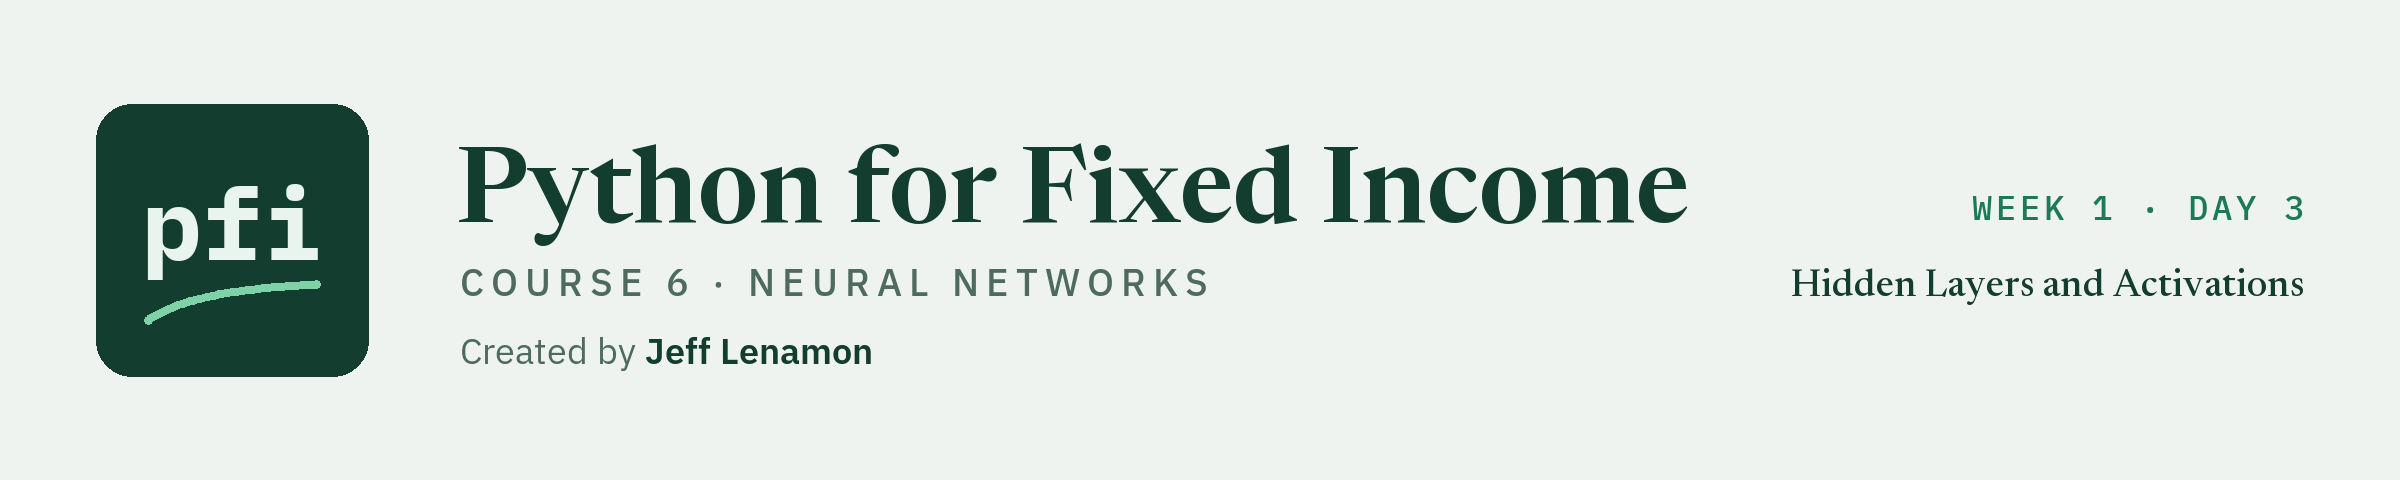

# Hidden Layers and Activations

Week 1, Day 3. A hidden layer is a row of neurons between the inputs and the output, each with an activation. Today: the activations, a two-unit layer by hand and in Excel, counting weights, a ladder of networks that changes one setting at a time, and a softmax network on five ordered rating buckets, scored by quadratic weighted kappa.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

**Data:** `benchmark.csv` and `ratings.csv`, 821 bonds of invented issuers: **synthetic**, made for this course by `tools/make_holdings.py`. No real issuer, price, or spread.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course06_neural_networks/week1/day3/03_hidden_layers_and_activations.ipynb)

Day 2 showed that one neuron is a logistic regression: the same loss, the same ranking, a straight line in the inputs pushed through the sigmoid. Today puts **hidden layers** between the inputs and that output neuron. Each hidden unit is a neuron of its own, and its **activation** bends its output, so a network of them can fit curves and interactions that one straight line cannot. Whether that helps on the card file is a question for the data, so the day ends with a ladder of six networks, each one setting away from the last, compared on rows held back for the purpose.

**The card rules, as on every card day.** The data is real: the UCI file of 30,000 credit card accounts in Taiwan in 2005, and consumer credit there differs from US credit. The four columns that describe people (`SEX`, `EDUCATION`, `MARRIAGE`, `AGE`) are never features and no output is grouped by them; every network uses the other 19 columns. Course 4's split is rebuilt with its 6,000 test rows closed (day 1's test-row rule). A network's output is the model probability of default in this file, or a flag at a threshold; a network fitted with class weights gives the model's score. No output of either kind is a credit decision for any person.

Today you will:

1. Compute the three activations, sigmoid, tanh, and ReLU, with numpy and Keras, and see their slopes.
2. Work a hidden layer of two units by hand, with weights you choose, in numpy and in Excel.
3. Write `forward_pass`, a network's output by numpy layer by layer, and check it against `model.predict`.
4. Count a network's weights by hand with `parameter_count`, and read `model.summary()`.
5. Climb a ladder of six networks, one setting at a time, chosen on the stopping rows.
6. See why a `Dense` layer with no activation adds nothing.
7. Report the chosen network once on the validation rows, beside the neuron.
8. Fit a softmax network to five ordered rating buckets on the synthetic benchmark bonds, and score it with accuracy and quadratic weighted kappa.

Q. Set up today's work folder: TensorFlow's settings, the thread settings, the seed, the card file and the benchmark files, and the modules as day 2 left them.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course06_neural_networks/requirements.txt
NEEDED = {
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "keras": "keras==3.15.1",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "tensorflow": "tensorflow==2.21.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

17 packages checked, all present


In [2]:
# today's setup: the TensorFlow and thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# TensorFlow writes start-up notices to stderr: these three lines must run before TensorFlow is imported
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These lines must run before numpy, pandas, scikit-learn, TensorFlow, or LightGBM is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("sklearn", "scikit-learn"), ("statsmodels", "statsmodels"), ("scipy", "scipy"), ("tensorflow", "tensorflow"), ("keras", "keras"), ("lightgbm", "lightgbm"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd
import tensorflow as tf
import keras

# one thread for TensorFlow too, set before TensorFlow runs anything
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
# TensorFlow's own Python notices are turned down to errors; on Windows the one it writes is that it has no GPU
# support there (day 1 explains it)
tf.get_logger().setLevel("ERROR")
# where TensorFlow has a deterministic version of an operation, use it
tf.config.experimental.enable_op_determinism()

# the versions the saved outputs of this notebook came from (course06_neural_networks/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "scipy": "1.18.1", "tensorflow": "2.21.0", "keras": "3.15.1", "lightgbm": "4.7.0", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42
# Keras's seed sets Python's, numpy's, and TensorFlow's random generators at once
keras.utils.set_random_seed(SEED)

# the kinds of device TensorFlow can use on this machine
devices = sorted({device.device_type for device in tf.config.list_physical_devices()})
print(f"Devices TensorFlow can use: {', '.join(devices)}")

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "credit_card_default.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course6_03_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["credit_card_default.csv", "benchmark.csv", "ratings.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, scipy 1.18.1, tensorflow 2.21.0, keras 3.15.1, lightgbm 4.7.0, matplotlib 3.11.2, pytest 9.1.1
Devices TensorFlow can use: CPU
Work folder: pfi_course6_03_qf3_06ry, in your temp folder
Data files from the data folder of the course repo: credit_card_default.csv, benchmark.csv, ratings.csv
SEED = 42


Q. Write `mlkit.py`, Course 4's complete module, and `ensemblekit.py`, Course 5's complete module, both unchanged. `netkit` imports them.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


In [4]:
%%writefile ensemblekit.py
"""ensemblekit: the pieces of ensembles, tuning, and rare-event modelling that the libraries leave to the analyst,
written down and tested.

Written day by day in Python for Fixed Income, Course 5: Advanced Machine Learning. It imports mlkit (Course 4's
module) and never changes it.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- The positive class is 1 (default, bankrupt). A row is flagged when its model output is at least the threshold.
- Course 5 never scores a row that Course 4 used as a test row. The course4_*_rows functions rebuild Course 4's
  splits exactly and return only the rows Course 5 may use; the closed rows are never returned.
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart.
- Every library call that can use more than one thread is given n_jobs=1, so every run gives the same digits.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from sklearn.model_selection import train_test_split  # Course 4's split, rebuilt

import mlkit  # Course 4's module: thresholds, metrics, splitters, and the no-leak check

# the card file: its outcome column and the 19 model columns (the four person columns are never features)
CARD_TARGET = "default payment next month"
CARD_FEATURES = ["LIMIT_BAL", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"] + \
    [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]


def course4_card_rows(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """Course 4's 60/20/20 split of the card file, rebuilt, without its test rows.

    Input: frame, the 30,000 accounts of credit_card_default.csv as read by pd.read_csv.
    Output: X_train (18,000 rows), X_valid (6,000 rows), y_train, y_valid, with the 19 model columns in
    CARD_FEATURES and the file's row labels. Course 4's 6,000 test rows are never returned.
    Convention: the same two calls as Course 4: train_test_split(test_size=0.2, stratify=y, random_state=42), then
    the remaining 80 percent split with test_size=0.25, stratified, same seed. The validation rows were used in
    Course 4 to choose a threshold and a pruning level, never to fit.
    Raises ValueError if a column is missing or the frame does not have 30,000 rows.
    """
    # check the frame is the whole card file
    missing = [name for name in CARD_FEATURES + [CARD_TARGET] if name not in frame.columns]
    if missing:
        raise ValueError(f"frame lacks the columns {missing}")
    if len(frame) != 30_000:
        raise ValueError(f"frame must hold the 30,000 card accounts, not {len(frame)}")
    X, y = frame[CARD_FEATURES], frame[CARD_TARGET]
    # Course 4's first cut puts 20 percent aside as test rows: they are dropped here, never returned
    X_rest, _, y_rest, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    # Course 4's second cut: a quarter of the rest (20 percent of the file) as validation rows
    X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest,
                                                          random_state=42)
    mlkit.assert_disjoint(X_train.index, X_valid.index)
    return X_train, X_valid, y_train, y_valid


def bootstrap_positions(n_rows: int, seed: int = 42) -> np.ndarray:
    """Draw n_rows row positions with replacement: one bootstrap sample.

    Input: n_rows, how many rows the data has (at least 1); seed, the random seed.
    Output: an array of n_rows positions from 0 to n_rows - 1, in the order drawn. A position can appear more than
    once, and some positions do not appear at all (about 36.8 percent of them for large n_rows).
    Convention: np.random.default_rng(seed).integers(0, n_rows, n_rows), so the same seed gives the same sample.
    Excel: =RANDBETWEEN(1,n) draws one position but takes no seed and changes at every recalculation.
    Raises ValueError if n_rows is below 1.
    """
    if n_rows < 1:
        raise ValueError(f"n_rows must be at least 1, not {n_rows}")
    # one generator per call, seeded, so the draw does not depend on anything drawn before
    rng = np.random.default_rng(seed)
    return rng.integers(0, n_rows, n_rows)


def out_of_bag(n_rows: int, drawn: np.ndarray) -> np.ndarray:
    """The positions a bootstrap sample never drew: its out-of-bag rows.

    Inputs: n_rows, how many rows the data has; drawn, the positions of a bootstrap sample.
    Output: the sorted positions from 0 to n_rows - 1 that are not in drawn.
    Convention: a model fitted on the drawn rows has never seen these rows, so they can score it.
    Raises ValueError if drawn is empty or holds a position outside 0 to n_rows - 1.
    """
    positions = np.asarray(drawn)
    if positions.size == 0:
        raise ValueError("drawn is empty")
    if positions.min() < 0 or positions.max() > n_rows - 1:
        raise ValueError(f"drawn holds a position outside 0 to {n_rows - 1}")
    # every position, minus the ones drawn at least once
    return np.setdiff1d(np.arange(n_rows), positions)


from sklearn.metrics import roc_auc_score  # ranking quality from probabilities


def bagged_proba(bagging, X: pd.DataFrame) -> np.ndarray:
    """Bagging by hand: the average of each fitted tree's class-1 probability, each on its own columns.

    Inputs: bagging, a fitted BaggingClassifier; X, the rows to score, with the columns it was fitted on.
    Output: one number per row, the mean over bagging.estimators_ of each tree's class-1 probability on the
    columns listed in bagging.estimators_features_. It equals bagging.predict_proba(X)[:, 1] within 1e-12.
    Convention: a tree whose bootstrap sample held only one class gives 0 for class 1 when that class is 0.
    Excel: with each tree's column of outputs pasted side by side, =AVERAGE(B2:K2) filled down.
    Raises ValueError if bagging is not fitted.
    """
    if not hasattr(bagging, "estimators_"):
        raise ValueError("bagging is not fitted: call fit first")
    # the trees were fitted on plain arrays of the chosen columns, so score them the same way
    values = np.asarray(X, dtype=float)
    total = np.zeros(len(values))
    for tree, columns in zip(bagging.estimators_, bagging.estimators_features_):
        proba = tree.predict_proba(values[:, columns])
        # the tree's classes are positions in bagging.classes_; class 1 is position 1
        position = np.flatnonzero(tree.classes_ == 1)
        total += proba[:, position[0]] if position.size else 0.0
    return total / len(bagging.estimators_)


def oob_auc(model, y_train) -> float:
    """ROC AUC of the out-of-bag probabilities of a bagged model or a random forest.

    Inputs: model, fitted with oob_score=True on the training rows; y_train, those rows' outcomes, in order.
    Output: roc_auc_score(y_train, model.oob_decision_function_[:, 1]): each row scored only by the trees that
    did not draw it.
    Convention: model.oob_score_ is the accuracy of the out-of-bag votes for a classifier, not ROC AUC; this
    function gives the ranking number the course compares models by.
    Raises ValueError if the model was fitted without oob_score=True, or if a row has no out-of-bag vote (too few
    trees, so some row was drawn by every tree).
    """
    if not hasattr(model, "oob_decision_function_"):
        raise ValueError("the model has no out-of-bag outputs: fit it with oob_score=True")
    proba = model.oob_decision_function_[:, 1]
    if np.isnan(proba).any():
        raise ValueError(f"{int(np.isnan(proba).sum())} rows have no out-of-bag vote: use more trees")
    return float(roc_auc_score(y_train, proba))


def tree_correlation(forest, X: pd.DataFrame) -> float:
    """How much the trees of an ensemble agree: the mean pairwise correlation of their class-1 outputs.

    Inputs: forest, a fitted random forest, extra-trees, or bagging model (anything with estimators_, and
    estimators_features_ for bagging); X, the rows to score (validation rows).
    Output: the mean of the upper triangle of np.corrcoef over the trees' class-1 probabilities on X: 1 means
    every tree gives the same ranking, 0 means no linear agreement.
    Convention: averaging trees removes less noise the more they agree; a random forest tries a random subset of
    columns at each split to lower this number.
    Excel: =CORREL(B2:B6001,C2:C6001) for one pair of pasted tree columns.
    Raises ValueError if the ensemble has fewer than two trees.
    """
    trees = list(forest.estimators_)
    if len(trees) < 2:
        raise ValueError(f"need at least two trees, the ensemble has {len(trees)}")
    # each tree was fitted on a plain array; bagging may give each tree its own columns
    values = np.asarray(X, dtype=float)
    columns = getattr(forest, "estimators_features_", [slice(None)] * len(trees))
    outputs = np.array([tree.predict_proba(values[:, cols])[:, -1] for tree, cols in zip(trees, columns)])
    # the correlation of every pair of trees, then the mean above the diagonal
    matrix = np.corrcoef(outputs)
    return float(matrix[np.triu_indices(len(trees), k=1)].mean())


from sklearn.inspection import permutation_importance  # the drop in a score when one column is shuffled


def importance_table(model, X_valid: pd.DataFrame, y_valid, scoring: str = "roc_auc", n_repeats: int = 5,
                     seed: int = 42) -> pd.DataFrame:
    """Two importance measures side by side: impurity importance and permutation importance.

    Inputs: model, a fitted tree ensemble with feature_importances_, fitted on a DataFrame; X_valid, y_valid,
    rows the model was NOT fitted on (validation rows); scoring, the score whose drop is measured; n_repeats, how
    many shuffles per column; seed, the random seed of the shuffles.
    Output: a DataFrame indexed by feature with columns impurity (model.feature_importances_, from the training
    rows, sums to 1), permutation (the mean drop in the score over n_repeats shuffles of that column),
    permutation_sd (their standard deviation), impurity_rank and permutation_rank (1 = largest), sorted by
    permutation, largest first.
    Convention: impurity importance is learned on the training rows and rewards columns the trees could split on
    to fit noise; permutation importance on unseen rows measures how much the score leans on a column there.
    Neither measure is a cause. permutation_importance runs with n_jobs=1.
    Raises ValueError if the model has no feature_importances_ (an unfitted model, or a linear model).
    """
    if not hasattr(model, "feature_importances_"):
        raise ValueError("the model has no feature_importances_: fit a tree ensemble first")
    # shuffle each column n_repeats times on the rows given and record the drop in the score
    result = permutation_importance(model, X_valid, y_valid, scoring=scoring, n_repeats=n_repeats,
                                    random_state=seed, n_jobs=1)
    table = pd.DataFrame({"impurity": model.feature_importances_, "permutation": result.importances_mean,
                          "permutation_sd": result.importances_std}, index=pd.Index(X_valid.columns, name="feature"))
    # rank 1 is the largest value; ties share the better rank
    table["impurity_rank"] = table["impurity"].rank(ascending=False, method="min").astype(int)
    table["permutation_rank"] = table["permutation"].rank(ascending=False, method="min").astype(int)
    return table.sort_values("permutation", ascending=False, kind="stable")


from sklearn.model_selection import cross_val_predict  # out-of-fold outputs, one per row


def course4_bench_rows(bench: pd.DataFrame, ratings: pd.DataFrame) -> pd.DataFrame:
    """Course 4's 615 training bonds of the synthetic benchmark, without its 206 test bonds.

    Inputs: bench, the 821 bonds of benchmark.csv; ratings, ratings.csv (rating and score).
    Output: the 615 training bonds with every column of bench plus score (the rating's number, 1 = AAA),
    log_oas (natural log of oas in bp), years (days from as_of_date to maturity / 365.25), and amount_bn
    (amount_outstanding in billions), with bench's row labels. Course 4's 206 test bonds are never returned.
    Convention: Course 4's split, train_test_split(test_size=0.25, random_state=42) on the joined rows. The bonds
    and their spreads are invented by the course's generator.
    Raises ValueError if bench does not hold 821 bonds.
    """
    if len(bench) != 821:
        raise ValueError(f"bench must hold the 821 benchmark bonds, not {len(bench)}")
    # the rating's number, joined row for row (each rating appears once in ratings)
    frame = bench.merge(ratings[["rating", "score"]], on="rating", how="left", validate="many_to_one")
    frame["log_oas"] = np.log(frame["oas"])
    dates = pd.to_datetime(frame["maturity"]) - pd.to_datetime(frame["as_of_date"])
    frame["years"] = dates.dt.days / 365.25
    frame["amount_bn"] = frame["amount_outstanding"] / 1e9
    # Course 4's split: the second part was its test set, dropped here
    train, _ = train_test_split(frame, test_size=0.25, random_state=42)
    return train


def oof_threshold(model, X, y, target_recall: float = 0.70, cv=None) -> tuple[float, np.ndarray]:
    """The course's threshold rule, applied to out-of-fold probabilities on the training rows.

    Inputs: model, an unfitted (or fitted) classifier with predict_proba; X, y, the training rows; target_recall,
    the share of defaults to catch; cv, a splitter (default mlkit.cv_folds(), stratified 5-fold, seed 42).
    Output: (threshold, proba): proba holds each training row's class-1 probability from the fold model that did
    not see it (cross_val_predict, n_jobs=1); threshold is mlkit.threshold_for_recall(y, proba, target_recall),
    the highest threshold whose out-of-fold recall is at least target_recall.
    Convention: the threshold is chosen on training rows only, so validation and test rows stay for reporting.
    cross_val_predict fits clones, so the caller's model is left as it was.
    Raises ValueError from mlkit.threshold_for_recall on a bad target or no row of class 1.
    """
    folds = cv if cv is not None else mlkit.cv_folds()
    proba = cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
    return mlkit.threshold_for_recall(y, proba, target_recall), proba


def samme_alpha(weighted_error: float, learning_rate: float = 1.0) -> float:
    """The weight AdaBoost gives one stump's vote, for two classes.

    Inputs: weighted_error, the stump's error with each row counted by its weight (above 0, below 0.5);
    learning_rate, the shrinkage AdaBoostClassifier applies (default 1.0).
    Output: learning_rate * ln((1 - e) / e), in natural logs. A stump right on 80 percent of the weight gets
    ln(4) = 1.3863; one barely better than a coin gets almost 0.
    Convention: the SAMME weight with two classes (its extra term ln(classes - 1) is ln 1 = 0); it equals
    AdaBoostClassifier's estimator_weights_.
    Excel: =LN((1-e)/e).
    Raises ValueError unless 0 < weighted_error < 0.5.
    """
    if not 0 < weighted_error < 0.5:
        raise ValueError(f"weighted_error must be above 0 and below 0.5, not {weighted_error}")
    return float(learning_rate * np.log((1 - weighted_error) / weighted_error))


def reweight(weights: np.ndarray, missed: np.ndarray, alpha: float) -> np.ndarray:
    """AdaBoost's new row weights after one round: the rows the stump missed count for more.

    Inputs: weights, the current row weights (non-negative); missed, 1 where the stump was wrong and 0 where it
    was right, the same length; alpha, the stump's weight (samme_alpha).
    Output: weights * exp(alpha * missed), divided by their sum so the new weights sum to 1.
    Excel: =w*EXP(alpha*miss) filled down, then each divided by the column's SUM.
    Raises ValueError if the lengths differ, the input is empty, or a weight is negative.
    """
    w = np.asarray(weights, dtype=float)
    m = np.asarray(missed, dtype=float)
    if w.size == 0 or w.shape != m.shape:
        raise ValueError(f"weights and missed must be non-empty and the same length, not {w.size} and {m.size}")
    if (w < 0).any():
        raise ValueError("weights must not be negative")
    # a missed row is multiplied by e^alpha, a correct row by 1
    new = w * np.exp(alpha * m)
    return new / new.sum()


from sklearn.tree import DecisionTreeRegressor  # one round's tree, fitted to the residuals


def boost_by_hand(X, y, n_rounds: int, learning_rate: float, max_depth: int, seed: int = 42) -> np.ndarray:
    """Gradient boosting for a squared error, by hand: start from the mean, then fit trees to the residuals.

    Inputs: X, the feature rows; y, the target (for example log_oas); n_rounds, how many trees; learning_rate,
    the fraction of each tree's output added; max_depth, each tree's depth; seed, each tree's random_state.
    Output: the fitted values on X after n_rounds: F0 = mean(y), then for each round
    F = F + learning_rate * tree.predict(X), with the tree fitted to the residuals y - F.
    Convention: equals GradientBoostingRegressor(n_estimators=n_rounds, learning_rate=..., max_depth=...,
    random_state=seed).predict(X) on the rows it was fitted on, within 1e-12. No criterion= is passed (scikit-learn
    1.9 deprecates "friedman_mse" for a regression tree).
    Excel: one round is =y-F, the two leaf means by AVERAGEIFS on either side of the stump's threshold, and
    =F+lr*IF(x<=t,left,right).
    Raises ValueError if n_rounds is below 1 or learning_rate is not positive.
    """
    if n_rounds < 1 or learning_rate <= 0:
        raise ValueError(f"n_rounds must be at least 1 and learning_rate positive, not {n_rounds}, {learning_rate}")
    target = np.asarray(y, dtype=float)
    # round 0: every row's fitted value is the mean
    fitted = np.full(target.size, target.mean())
    for _ in range(n_rounds):
        # fit a small tree to what is still unexplained, then add a fraction of it
        tree = DecisionTreeRegressor(max_depth=max_depth, random_state=seed).fit(X, target - fitted)
        fitted = fitted + learning_rate * tree.predict(X)
    return fitted


def mae_bp(log_true, log_fitted) -> float:
    """Mean absolute error in bp of a model fitted on log spreads.

    Inputs: log_true and log_fitted, natural logs of spreads in bp, the same length.
    Output: mean(|exp(log_true) - exp(log_fitted)|), in bp.
    Convention: the course's benchmark metric; exp of a fitted log is a median-type value, not a mean.
    Excel: =AVERAGE(ABS(EXP(a)-EXP(b))).
    Raises ValueError if the inputs are empty or of different lengths.
    """
    true, fitted = np.asarray(log_true, dtype=float), np.asarray(log_fitted, dtype=float)
    if true.size == 0 or true.shape != fitted.shape:
        raise ValueError(f"inputs must be non-empty and the same length, not {true.size} and {fitted.size}")
    return float(np.mean(np.abs(np.exp(true) - np.exp(fitted))))


def early_stopping_rows(X_train, y_train, fraction: float = 0.2, seed: int = 42) -> tuple:
    """Carve stopping rows out of the training rows, for early stopping, so no report row chooses the trees.

    Inputs: X_train, y_train, the training rows; fraction, the share set aside to stop on (above 0, below 0.5);
    seed, the split's seed.
    Output: X_fit, X_stop, y_fit, y_stop: a stratified split of the training rows only. Fit on X_fit and pass
    (X_stop, y_stop) as eval_set; validation and test rows are never an eval_set.
    Convention: train_test_split(test_size=fraction, stratify=y_train, random_state=seed), checked with
    mlkit.assert_disjoint.
    Raises ValueError unless 0 < fraction < 0.5.
    """
    if not 0 < fraction < 0.5:
        raise ValueError(f"fraction must be above 0 and below 0.5, not {fraction}")
    X_fit, X_stop, y_fit, y_stop = train_test_split(X_train, y_train, test_size=fraction, stratify=y_train,
                                                    random_state=seed)
    mlkit.assert_disjoint(X_fit.index, X_stop.index)
    return X_fit, X_stop, y_fit, y_stop


def scale_pos_weight(y) -> float:
    """XGBoost's weight for the rare class: negatives divided by positives.

    Input: y, the outcomes of the training rows (0 or 1).
    Output: (number of 0s) / (number of 1s). On Course 4's card training rows about 3.5.
    Convention: passed as XGBClassifier(scale_pos_weight=...); the model's output is then a score whose average
    is above the outcome rate, not a probability.
    Raises ValueError if y is empty or has no positive.
    """
    outcomes = np.asarray(y)
    positives = int((outcomes == 1).sum())
    if positives == 0:
        raise ValueError("y has no row of class 1")
    return float((outcomes == 0).sum() / positives)


def stack_inputs(models: dict, X, y, cv=None) -> pd.DataFrame:
    """The columns a stack's final model is fitted on: each base model's out-of-fold class-1 probability.

    Inputs: models, {name: classifier with predict_proba}; X, y, the training rows; cv, a splitter (default
    mlkit.cv_folds()).
    Output: a DataFrame with X's row labels and one column per model, in the order of models: each row's
    probability from the fold model that did not see it (cross_val_predict, n_jobs=1).
    Convention: what StackingClassifier(stack_method="predict_proba", cv=cv) feeds its final estimator for two
    classes. A final model fitted on in-sample outputs would learn to trust the base models too much.
    Raises ValueError if models is empty.
    """
    if not models:
        raise ValueError("models is empty")
    folds = cv if cv is not None else mlkit.cv_folds()
    columns = {name: cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
               for name, model in models.items()}
    return pd.DataFrame(columns, index=X.index)


def bootstrap_interval(y_true, proba, metric, n_boot: int = 1000, level: float = 0.95,
                       seed: int = 42) -> tuple[float, float]:
    """A percentile interval for a metric, from resampling the scored rows.

    Inputs: y_true, the outcomes of the scored rows (0 or 1); proba, the model's outputs on them; metric, a
    function metric(y_true, proba) such as roc_auc_score; n_boot, how many resamples; level, the interval's
    coverage (0.95 for a 95 percent interval); seed, the resampling seed.
    Output: (lower, upper), numpy.percentile (linear) of the n_boot values at (1 - level) / 2 and (1 + level) / 2.
    Convention: each resample draws len(y_true) rows with replacement by np.random.default_rng(seed); a resample
    holding one class only is drawn again. The interval describes the noise from which rows happened to be
    scored, not the noise from refitting the model.
    Excel: =PERCENTILE.INC(range,0.025) and =PERCENTILE.INC(range,0.975) on the pasted resampled values.
    Raises ValueError on inputs of different lengths, fewer than both classes, n_boot below 1, or level outside
    (0, 1).
    """
    actual, scores = np.asarray(y_true), np.asarray(proba, dtype=float)
    if actual.size == 0 or actual.shape != scores.shape:
        raise ValueError(f"y_true and proba must be non-empty and the same length, not {actual.size} and {scores.size}")
    if len(np.unique(actual)) < 2:
        raise ValueError("y_true must hold both classes")
    if n_boot < 1 or not 0 < level < 1:
        raise ValueError(f"n_boot must be at least 1 and level between 0 and 1, not {n_boot}, {level}")
    rng = np.random.default_rng(seed)
    values = []
    while len(values) < n_boot:
        rows = rng.integers(0, actual.size, actual.size)
        # a resample with one class has no ROC AUC; draw again
        if len(np.unique(actual[rows])) < 2:
            continue
        values.append(metric(actual[rows], scores[rows]))
    lower, upper = np.percentile(values, [100 * (1 - level) / 2, 100 * (1 + level) / 2])
    return float(lower), float(upper)


from sklearn.model_selection import cross_val_score  # one score per fold


def course4_polish_rows(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Course 4's 4,680 training rows of the Polish bankruptcy file, without its 1,170 test rows.

    Input: frame, the 5,910 rows of polish_bankruptcy_5year.csv read with float_precision="round_trip".
    Output: X_train (Attr1 to Attr64, missing values kept) and y_train (class), 4,680 rows, 326 of them bankrupt,
    with the file's row labels. Course 4's 1,170 test rows are never returned.
    Convention: Course 4's capstone steps: exact duplicate rows dropped (5,910 to 5,850), then
    train_test_split(test_size=0.2, stratify=y, random_state=42).
    Raises ValueError if the frame does not hold 5,910 rows with a class column.
    """
    if len(frame) != 5_910 or "class" not in frame.columns:
        raise ValueError(f"frame must be the 5,910 rows of the Polish file with a class column, not {len(frame)} rows")
    unique = frame.drop_duplicates()
    X, y = unique.drop(columns="class"), unique["class"]
    # Course 4's split: the second part was its test set, dropped here
    X_train, _, y_train, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    return X_train, y_train


def nested_score(search, X, y, outer=None, scoring: str = "average_precision") -> pd.Series:
    """An honest score for a tuned model: the whole search is repeated inside each outer fold.

    Inputs: search, an unfitted RandomizedSearchCV or GridSearchCV that carries its own inner cv; X, y, the
    training rows; outer, the outer splitter (default mlkit.cv_folds()); scoring, the metric.
    Output: one score per outer fold, indexed fold_1, fold_2, ...: each fold's search tunes on the other folds
    only and is scored on its own held-out rows (cross_val_score, n_jobs=1).
    Convention: a search's best_score_ is the best of many noisy numbers and is not an honest score of the model it
    chose; the mean of this Series is.
    Raises ValueError if the search has no inner cv.
    """
    if getattr(search, "cv", None) is None:
        raise ValueError("give the search its own inner cv, for example StratifiedKFold(3, shuffle=True, random_state=42)")
    folds = outer if outer is not None else mlkit.cv_folds()
    scores = cross_val_score(search, X, y, cv=folds, scoring=scoring, n_jobs=1)
    return pd.Series(scores, index=[f"fold_{i}" for i in range(1, len(scores) + 1)], name=scoring)


def search_table(search, top: int = 5) -> pd.DataFrame:
    """A fitted search's results as a short table, best first.

    Inputs: search, a fitted RandomizedSearchCV or GridSearchCV; top, how many candidates to keep.
    Output: columns rank, mean, sd (the mean and standard deviation of the fold scores, ddof=0, as cv_results_),
    then one column per searched parameter (the param_ prefix dropped), sorted by rank.
    Excel: =AVERAGE and =STDEV.P of a candidate's five fold scores give its mean and sd (STDEV.S does not).
    Raises ValueError if the search is not fitted.
    """
    if not hasattr(search, "cv_results_"):
        raise ValueError("the search is not fitted: call fit first")
    results = pd.DataFrame(search.cv_results_)
    params = [name for name in results.columns if name.startswith("param_")]
    table = results[["rank_test_score", "mean_test_score", "std_test_score"] + params]
    table.columns = ["rank", "mean", "sd"] + [name[len("param_"):] for name in params]
    return table.sort_values("rank", kind="stable").head(top).reset_index(drop=True)


from sklearn.base import BaseEstimator, TransformerMixin  # what makes a class a scikit-learn transformer
from sklearn.utils.validation import check_is_fitted  # stops a transformer used before fit


def safe_ratio(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    """A ratio of two columns that is never infinite: missing where the denominator is 0 or either side is missing.

    Inputs: numerator, denominator, two Series with the same row labels.
    Output: numerator / denominator as floats, with NaN where the denominator is 0 or either value is missing.
    Convention: a model that handles missing values (or an imputer inside a pipeline) then deals with those rows;
    an infinity would break most estimators.
    Excel: =IF(OR(B2=0,B2="",A2=""),NA(),A2/B2), where =A2/B2 alone gives #DIV/0!.
    Raises ValueError if the two Series do not have the same row labels.
    """
    if not numerator.index.equals(denominator.index):
        raise ValueError("numerator and denominator must have the same row labels")
    defined = denominator.ne(0) & numerator.notna() & denominator.notna()
    # divide only where the ratio is defined; every other row stays NaN
    return numerator.astype(float).div(denominator.astype(float).where(defined)).where(defined)


class ClipToTraining(TransformerMixin, BaseEstimator):
    """Clip each column to bounds learned from the rows it is fitted on (by default the 1st and 99th percentiles).

    Inside a pipeline, fit sees only each fold's training rows, so the bounds never come from held-out rows.
    Parameters: lower, upper, the quantiles (0 <= lower < upper <= 1).
    Fitted attributes: lower_, upper_, one bound per column (numpy.nanquantile, linear, missing values ignored);
    n_features_in_; feature_names_in_ when fitted on a DataFrame.
    transform returns a float array; a missing value stays missing.
    Excel: =PERCENTILE.INC(training_range,0.01) and 0.99 give the bounds; =MIN(MAX(x,low),high) clips.
    """

    def __init__(self, lower: float = 0.01, upper: float = 0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        if not 0 <= self.lower < self.upper <= 1:
            raise ValueError(f"need 0 <= lower < upper <= 1, not {self.lower}, {self.upper}")
        values = np.asarray(X, dtype=float)
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = values.shape[1]
        # each column's bounds, from these rows only
        self.lower_ = np.nanquantile(values, self.lower, axis=0)
        self.upper_ = np.nanquantile(values, self.upper, axis=0)
        return self

    def transform(self, X):
        check_is_fitted(self, ["lower_", "upper_"])
        values = np.asarray(X, dtype=float)
        if values.shape[1] != self.n_features_in_:
            raise ValueError(f"X has {values.shape[1]} columns, the transformer was fitted on {self.n_features_in_}")
        return np.clip(values, self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, ["lower_", "upper_"])
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        if hasattr(self, "feature_names_in_"):
            return self.feature_names_in_
        return np.asarray([f"x{i}" for i in range(self.n_features_in_)], dtype=object)


def class_counts_after(sampler, X, y) -> pd.Series:
    """How many rows of each class a resampler leaves: for showing what a sampler does.

    Inputs: sampler, an imbalanced-learn sampler such as SMOTE(random_state=42); X, y, rows with no missing value.
    Output: the count of each class after sampler.fit_resample(X, y), indexed by class.
    Convention: a demonstration only. Rows a model is scored on are never resampled; resampling belongs inside an
    imblearn pipeline, where cross-validation resamples each fold's training rows only.
    """
    _, y_resampled = sampler.fit_resample(X, y)
    return pd.Series(y_resampled).value_counts().sort_index()


def prior_correction(score, fitted_rate: float, true_rate: float) -> np.ndarray:
    """Move a score from a model fitted at one outcome rate back to the rate of the real rows.

    Inputs: score, the model's outputs (between 0 and 1); fitted_rate, the outcome rate of the rows the model was
    fitted on (0.5 after SMOTE to balance); true_rate, the outcome rate of the real training rows.
    Output: each score's odds multiplied by k = (true_rate / (1 - true_rate)) / (fitted_rate / (1 - fitted_rate)),
    turned back into a number between 0 and 1: s * k / (s * k + 1 - s).
    Convention: a closed form that assumes resampling changed only the class shares; it leaves the ranking of rows
    unchanged. Equal rates give the score back.
    Excel: k in one cell, =(t/(1-t))/(f/(1-f)), then =p*k/(p*k+1-p) filled down.
    Raises ValueError if a rate is not strictly between 0 and 1 or a score is outside [0, 1].
    """
    for name, rate in (("fitted_rate", fitted_rate), ("true_rate", true_rate)):
        if not 0 < rate < 1:
            raise ValueError(f"{name} must be strictly between 0 and 1, not {rate}")
    s = np.asarray(score, dtype=float)
    if s.size == 0 or (s < 0).any() or (s > 1).any():
        raise ValueError("score must be non-empty and between 0 and 1")
    # the factor that moves odds from the fitted rate to the true rate
    k = (true_rate / (1 - true_rate)) / (fitted_rate / (1 - fitted_rate))
    return s * k / (s * k + 1 - s)


import re  # whole-word search

# words that turn a description of a model into a claim about causes; a reminder, not a proof
EXPLANATION_WORDS = ["cause", "causes", "caused", "driver", "drivers", "drives", "reason", "reasons", "because"]


def shap_table(shap_values, top: int | None = None) -> pd.DataFrame:
    """Mean absolute SHAP value per feature, largest first.

    Inputs: shap_values, a shap.Explanation for one output (rows by features), for example
    shap.TreeExplainer(model)(X); top, how many features to keep (all if None).
    Output: a DataFrame indexed by feature with columns mean_abs_shap (the average size of the feature's
    contribution to the model's log-odds, in log-odds) and rank (1 = largest).
    Convention: a SHAP value describes how the model's output for a row splits across features; it is not the
    effect of changing a feature and not a cause.
    Excel: =AVERAGE(ABS(column)) on a pasted column of SHAP values.
    Raises ValueError if the values are not one row per observation and one column per feature.
    """
    values = np.asarray(shap_values.values, dtype=float)
    if values.ndim != 2 or values.shape[1] != len(shap_values.feature_names):
        raise ValueError(f"expected rows by features, got shape {values.shape}")
    table = pd.DataFrame({"mean_abs_shap": np.abs(values).mean(axis=0)},
                         index=pd.Index(shap_values.feature_names, name="feature"))
    table = table.sort_values("mean_abs_shap", ascending=False, kind="stable")
    table["rank"] = np.arange(1, len(table) + 1)
    return table if top is None else table.head(top)


def assert_additive(shap_values, raw_score, tol: float = 1e-9) -> None:
    """Stop unless each row's SHAP values add up to the model's raw output (log-odds).

    Inputs: shap_values, a shap.Explanation for one output; raw_score, the model's log-odds for the same rows
    (LightGBM: predict(X, raw_score=True); XGBoost: predict(X, output_margin=True)); tol, the largest gap allowed
    (1e-9 for LightGBM; 1e-5 for XGBoost, which computes in float32).
    Output: None when base value + the row's SHAP values equals raw_score in every row within tol.
    Convention: the contributions add up in log-odds, not in probability; mlkit.logistic_probability turns the sum
    into the model's probability.
    Raises AssertionError naming the largest gap and its row position, and ValueError on lengths that differ.
    """
    values = np.asarray(shap_values.values, dtype=float)
    raw = np.asarray(raw_score, dtype=float)
    if values.ndim != 2 or values.shape[0] != raw.size:
        raise ValueError(f"shap_values has {values.shape[0]} rows and raw_score {raw.size}")
    # base value plus the row's contributions, against the model's own log-odds
    gaps = np.abs(np.asarray(shap_values.base_values, dtype=float) + values.sum(axis=1) - raw)
    worst = int(np.argmax(gaps))
    if gaps[worst] > tol:
        raise AssertionError(f"SHAP values do not add up to raw_score: largest gap {gaps[worst]:.3g} at row "
                             f"position {worst} (tolerance {tol:g}); raw_score must be log-odds, not a probability")


def assert_described(text: str) -> None:
    """Stop if a written description uses a forecast word or a cause word.

    Input: text, a description of what a model shows.
    Output: None if the text passes mlkit.assert_descriptive and holds no word of EXPLANATION_WORDS as a whole word,
    in any case.
    Convention: the lists are a reminder, not a proof. "because" is on the list so the writer looks again at every
    causal sentence; a description that needs it rewrites the sentence.
    Raises ValueError naming the words found.
    """
    mlkit.assert_descriptive(text)
    found = [word for word in EXPLANATION_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses cause or explanation words: {found}")

Writing ensemblekit.py


Q. Write `netkit.py` and `test_netkit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [5]:
%%writefile netkit.py
"""netkit: the pieces of neural networks that Keras leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 6: Neural Networks. It imports mlkit (Course 4's module) and
ensemblekit (Course 5's module) and never changes either.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one. Every function that builds a Keras model calls
  keras.utils.set_random_seed(seed) first, so a model's numbers do not depend on what ran before it.
- Keras runs quietly: verbose=0 on every fit, predict, and evaluate.
- The positive class is 1 (default, bankrupt). A row is flagged when its model output is at least the threshold.
- Course 6 never scores a row that an earlier course used as a test row: rows come from ensemblekit.course4_*_rows.
- Rows that fit a network, rows that stop or choose, and rows that report a result are kept apart. A scaler is
  fitted on the fit rows only (fit_arrays).
- Changes and errors on the Treasury curve are in basis points (bp).
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import os

# TensorFlow reads these when it is imported. setdefault keeps whatever a notebook's setup cell already set, and
# quiets TensorFlow's start-up notices when the tests run from PowerShell.
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
import tensorflow as tf  # tensors and automatic gradients
import keras  # networks: layers, optimizers, losses

import ensemblekit  # Course 5's module: the card, benchmark, and Polish rows, stopping rows, mae_bp
import mlkit  # Course 4's module: folds, thresholds, metrics, and the no-leak checks


def _labels_and_scores(y, p) -> tuple[np.ndarray, np.ndarray]:
    """y and p as float64 arrays of the same length, y holding only 0 and 1; raises ValueError otherwise."""
    labels = np.asarray(y, dtype=float).ravel()
    scores = np.asarray(p, dtype=float).ravel()
    if labels.size == 0 or labels.size != scores.size:
        raise ValueError(f"y and p must be non-empty and the same length, not {labels.size} and {scores.size}")
    if not np.isin(labels, (0.0, 1.0)).all():
        raise ValueError("y must hold only 0 and 1")
    return labels, scores


def mean_log_loss(y, p, epsilon: float = 1e-7) -> float:
    """The mean log loss (binary cross-entropy) of outputs p for outcomes y.

    Inputs: y, outcomes (0 or 1); p, the model's outputs, between 0 and 1, the same length; epsilon, how far from 0
    and 1 each output is clipped.
    Output: mean of -(y ln p + (1 - y) ln(1 - p)), with p clipped to [epsilon, 1 - epsilon] as Keras clips (its
    default epsilon is 1e-7). Equals sklearn.metrics.log_loss within 1e-12 when no output is clipped.
    Excel: =-(B2*LN(C2)+(1-B2)*LN(1-C2)) filled down, then =AVERAGE of the column.
    Raises ValueError on lengths that differ or labels other than 0 and 1.
    """
    labels, scores = _labels_and_scores(y, p)
    # keep every output inside (0, 1), so no logarithm is of 0
    clipped = np.clip(scores, epsilon, 1 - epsilon)
    return float(np.mean(-(labels * np.log(clipped) + (1 - labels) * np.log(1 - clipped))))


def _neuron_inputs(w, b: float, X, y) -> tuple[np.ndarray, float, np.ndarray, np.ndarray]:
    """w, X, y as float64 arrays that line up with each other; raises ValueError otherwise."""
    weights = np.asarray(w, dtype=float).ravel()
    rows = np.asarray(X, dtype=float)
    if rows.ndim != 2 or rows.shape[0] == 0:
        raise ValueError(f"X must be a non-empty 2-D array of rows by columns, not shape {rows.shape}")
    if rows.shape[1] != weights.size:
        raise ValueError(f"X has {rows.shape[1]} columns but w has {weights.size} weights")
    labels, _ = _labels_and_scores(y, np.zeros(rows.shape[0]))
    return weights, float(b), rows, labels


def log_loss_gradient(w, b: float, X, y) -> tuple[np.ndarray, float]:
    """The gradient of the mean log loss of one sigmoid neuron, worked by hand.

    Inputs: w, one weight per column of X; b, the intercept; X, the rows (rows by columns); y, the outcomes (0 or 1).
    Output: (gradient for the weights, gradient for the intercept), in float64: ((p - y) @ X / n, mean(p - y)),
    where p = 1 / (1 + exp(-(X @ w + b))) and n is the number of rows.
    Convention: the gradient is averaged over the rows, as Keras averages the loss over a batch. Equals
    tf.GradientTape on float64 tensors within 1e-12.
    Excel: =SUMPRODUCT(C2:C18001-B2:B18001,A2:A18001)/ROWS(A2:A18001) for a weight and
    =SUMPRODUCT(C2:C18001-B2:B18001)/ROWS(A2:A18001) for the intercept.
    Raises ValueError if the shapes do not line up or y holds labels other than 0 and 1.
    """
    weights, intercept, rows, labels = _neuron_inputs(w, b, X, y)
    # the neuron's output for each row, then how far it is from the outcome
    p = 1 / (1 + np.exp(-(rows @ weights + intercept)))
    error = p - labels
    return error @ rows / rows.shape[0], float(error.mean())


def gradient_step(w, b: float, X, y, learning_rate: float) -> tuple[np.ndarray, float]:
    """One full-batch step of gradient descent for one sigmoid neuron.

    Inputs: w, b, X, y as log_loss_gradient; learning_rate, the size of the step (above 0).
    Output: (w - learning_rate * gradient for the weights, b - learning_rate * gradient for the intercept).
    Convention: a learning rate that is too large makes the loss rise instead of fall.
    Excel: =$H$2-$H$5*$H$7 for each weight, with the gradient in its own cell.
    Raises ValueError unless learning_rate > 0, and as log_loss_gradient.
    """
    if not learning_rate > 0:
        raise ValueError(f"learning_rate must be above 0, not {learning_rate}")
    gradient_w, gradient_b = log_loss_gradient(w, b, X, y)
    return np.asarray(w, dtype=float).ravel() - learning_rate * gradient_w, float(b) - learning_rate * gradient_b


from sklearn.base import clone  # a fresh, unfitted copy of a transformer


def fit_arrays(transformer, X_fit, *others) -> tuple:
    """Fit a scaler (or any scikit-learn transformer) on the fit rows only, then transform every set of rows.

    Inputs: transformer, an unfitted scikit-learn transformer, for example StandardScaler(), a ColumnTransformer,
    or a Pipeline of an imputer and a QuantileTransformer; X_fit, the rows the network is fitted on; others, any
    other sets of rows (stopping rows, validation rows, a held-out fold).
    Output: (fitted, A_fit, *A_others): a clone of transformer fitted on X_fit only, and float32 arrays of X_fit and
    of each of others transformed by that fitted copy.
    Convention: this is the course's one way to scale rows for a network. The rows in others are never seen by the
    fit, so their statistics cannot leak into the scaling.
    Raises ValueError if X_fit is empty.
    """
    if len(X_fit) == 0:
        raise ValueError("X_fit is empty")
    # a clone, so the transformer passed in stays unfitted and can be used again
    fitted = clone(transformer).fit(X_fit)
    arrays = [np.asarray(fitted.transform(rows), dtype="float32") for rows in (X_fit, *others)]
    return (fitted, *arrays)


def neuron_coefficients(model, names: list[str]) -> pd.Series:
    """The intercept and weights of a network that is one neuron.

    Inputs: model, a Keras model with exactly one Dense layer of one unit; names, the input columns' names.
    Output: a Series indexed intercept, then names, in the model's input units (scaled inputs give weights per
    standard deviation). With a sigmoid output these are log-odds coefficients, as a logistic regression's.
    Raises ValueError if the model has another Dense layer, the layer has more than one unit, or names has the
    wrong length.
    """
    dense = [layer for layer in model.layers if isinstance(layer, keras.layers.Dense)]
    if len(dense) != 1 or dense[0].units != 1:
        raise ValueError("the model must have exactly one Dense layer with one unit")
    kernel, bias = dense[0].get_weights()
    if len(names) != kernel.shape[0]:
        raise ValueError(f"the layer has {kernel.shape[0]} inputs but {len(names)} names were given")
    return pd.Series(np.concatenate([bias, kernel[:, 0]]).astype(float), index=["intercept", *names])

Writing netkit.py


In [6]:
%%writefile test_netkit.py
"""Tests for netkit.py.

Expected values come from TensorFlow, Keras, or scikit-learn on the same inputs, or from small examples worked by
hand. Every test uses small seeded arrays: no course data file, no network connection.
Run from this folder with:  python -m pytest
"""
import keras
import numpy as np
import pytest
import tensorflow as tf
from sklearn.metrics import log_loss

import netkit

SEED = 42


def small_rows(n: int = 200, k: int = 3) -> tuple[np.ndarray, np.ndarray]:
    """n seeded rows of k standard normal columns and 0/1 outcomes that depend on the first column."""
    rng = np.random.default_rng(SEED)
    X = rng.normal(size=(n, k))
    y = (X[:, 0] + rng.normal(size=n) > 0.5).astype(float)
    return X, y


def test_mean_log_loss_matches_sklearn():
    rng = np.random.default_rng(SEED)
    y = rng.integers(0, 2, 50)
    p = rng.uniform(0.05, 0.95, 50)
    assert netkit.mean_log_loss(y, p) == pytest.approx(log_loss(y, p), abs=1e-12)
    with pytest.raises(ValueError):
        netkit.mean_log_loss([0, 1], [0.5])
    with pytest.raises(ValueError):
        netkit.mean_log_loss([0, 2], [0.5, 0.5])


def test_mean_log_loss_clips_like_keras():
    # an output of exactly 0 for an outcome of 1 is clipped to 1e-7, as Keras clips, so the loss is finite
    y, p = np.array([1.0, 0.0]), np.array([0.0, 0.0])
    expected = -(np.log(1e-7) + np.log(1 - 1e-7)) / 2
    assert netkit.mean_log_loss(y, p) == pytest.approx(expected, rel=1e-12)
    keras_loss = keras.losses.binary_crossentropy(y.astype("float32"), p.astype("float32"))
    assert netkit.mean_log_loss(y, p) == pytest.approx(float(keras_loss), rel=1e-6)


def test_log_loss_gradient_matches_tape():
    X, y = small_rows()
    w, b = np.array([0.5, -0.25, 0.1]), -1.0
    weights = tf.Variable(w)
    intercept = tf.Variable(b, dtype=tf.float64)
    with tf.GradientTape() as tape:
        p = tf.sigmoid(tf.linalg.matvec(tf.constant(X), weights) + intercept)
        loss = tf.reduce_mean(-(y * tf.math.log(p) + (1 - y) * tf.math.log(1 - p)))
    tape_w, tape_b = tape.gradient(loss, [weights, intercept])
    hand_w, hand_b = netkit.log_loss_gradient(w, b, X, y)
    assert np.allclose(hand_w, tape_w.numpy(), rtol=0, atol=1e-12)
    assert hand_b == pytest.approx(float(tape_b), abs=1e-12)


def test_log_loss_gradient_hand_case():
    # two rows, one column, w = 0 and b = 0: both outputs are 0.5
    # weight: ((0.5 - 1) * 2 + (0.5 - 0) * 4) / 2 = 0.5; intercept: ((0.5 - 1) + (0.5 - 0)) / 2 = 0
    gradient_w, gradient_b = netkit.log_loss_gradient([0.0], 0.0, [[2.0], [4.0]], [1, 0])
    assert gradient_w.tolist() == pytest.approx([0.5], abs=1e-12)
    assert gradient_b == pytest.approx(0.0, abs=1e-12)
    with pytest.raises(ValueError):
        netkit.log_loss_gradient([0.0, 1.0], 0.0, [[2.0], [4.0]], [1, 0])


def test_gradient_step_lowers_loss():
    X, y = small_rows()
    w, b = np.zeros(3), 0.0

    def loss(w, b):
        return netkit.mean_log_loss(y, 1 / (1 + np.exp(-(X @ w + b))))

    before = loss(w, b)
    for _ in range(20):
        w, b = netkit.gradient_step(w, b, X, y, learning_rate=0.5)
    assert loss(w, b) < before


def test_gradient_step_rejects_learning_rate():
    X, y = small_rows(10)
    for rate in (0.0, -0.1):
        with pytest.raises(ValueError):
            netkit.gradient_step(np.zeros(3), 0.0, X, y, learning_rate=rate)


from sklearn.preprocessing import StandardScaler


def test_fit_arrays_fits_on_fit_rows_only():
    X, _ = small_rows()
    X_fit, X_other = X[:150], X[150:] + 10.0
    fitted, A_fit, A_other = netkit.fit_arrays(StandardScaler(), X_fit, X_other)
    # the scaler's statistics are the fit rows' alone
    assert np.allclose(fitted.mean_, X_fit.mean(axis=0), rtol=0, atol=1e-12)
    assert np.allclose(fitted.scale_, X_fit.std(axis=0), rtol=0, atol=1e-12)
    assert np.allclose(A_other, (X_other - X_fit.mean(axis=0)) / X_fit.std(axis=0), rtol=0, atol=1e-5)
    with pytest.raises(ValueError):
        netkit.fit_arrays(StandardScaler(), X[:0])


def test_fit_arrays_returns_float32():
    X, _ = small_rows()
    scaler = StandardScaler()
    _, A_fit, A_a, A_b = netkit.fit_arrays(scaler, X[:100], X[100:150], X[150:])
    assert [a.dtype for a in (A_fit, A_a, A_b)] == [np.float32] * 3
    assert [a.shape for a in (A_fit, A_a, A_b)] == [(100, 3), (50, 3), (50, 3)]
    # the transformer passed in is left unfitted
    assert not hasattr(scaler, "mean_")


def one_neuron(n_inputs: int) -> keras.Model:
    keras.utils.set_random_seed(SEED)
    return keras.Sequential([keras.Input(shape=(n_inputs,)), keras.layers.Dense(1, activation="sigmoid", name="neuron")],
                            name="one_neuron")


def test_neuron_coefficients_names_and_values():
    model = one_neuron(2)
    model.layers[0].set_weights([np.array([[0.75], [-0.5]], dtype="float32"), np.array([0.25], dtype="float32")])
    coefficients = netkit.neuron_coefficients(model, ["PAY_0", "LIMIT_BAL"])
    assert coefficients.index.tolist() == ["intercept", "PAY_0", "LIMIT_BAL"]
    assert coefficients.tolist() == pytest.approx([0.25, 0.75, -0.5], abs=1e-7)
    with pytest.raises(ValueError):
        netkit.neuron_coefficients(model, ["PAY_0"])


def test_neuron_coefficients_rejects_hidden_layer():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(2,)), keras.layers.Dense(4, activation="relu", name="hidden"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="two_layers")
    with pytest.raises(ValueError):
        netkit.neuron_coefficients(model, ["a", "b"])

Writing test_netkit.py


Q. Import the modules.

In [7]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import mlkit
import ensemblekit
import netkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(ensemblekit)
importlib.reload(netkit)

# the functions defined in netkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(netkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "netkit" and not name.startswith("_")]
print(f"netkit functions: {functions}")

netkit functions: ['mean_log_loss', 'log_loss_gradient', 'gradient_step', 'fit_arrays', 'neuron_coefficients']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [8]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [9]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* The setup cell is day 1's, line for line; day 1 explains each line. `netkit.py` and `test_netkit.py` are the reference files at the end of day 2: 10 tests.

Q. Run day 2's tests before adding anything.

In [10]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_netkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..........                                                               [100%]
10 passed in 5.90s



* `10 passed`: the start of today is sound.

Q. Load the card rows, carve the fit and stopping rows, and scale the 19 columns on the fit rows only.

In [11]:
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

# Course 4's training and validation rows (the test rows are never returned), then Course 5's stratified fifth to stop on
card = pd.read_csv("credit_card_default.csv")
X_train, X_valid, y_train, y_valid = ensemblekit.course4_card_rows(card)
X_fit, X_stop, y_fit, y_stop = ensemblekit.early_stopping_rows(X_train, y_train)
assert not set(X_train.columns) & {"SEX", "EDUCATION", "MARRIAGE", "AGE"}, "a person column is in the features"

# day 2's one door for scaling: fitted on the fit rows only, then applied to every set of rows, as float32
scaler, A_fit, A_stop, A_valid = netkit.fit_arrays(StandardScaler(), X_fit, X_stop, X_valid)
y_fit_array = y_fit.to_numpy("float32")
n_inputs = A_fit.shape[1]
print(f"fit rows {A_fit.shape}, stopping rows {A_stop.shape}, validation rows {A_valid.shape}, dtype {A_fit.dtype}")

fit rows (14400, 19), stopping rows (3600, 19), validation rows (6000, 19), dtype float32


* 14,400 rows to fit, 3,600 to stop or choose on, 6,000 to report on once at the end, each with 19 columns in float32. The scaler saw only the fit rows.

## 3.1 Activations as Functions

**How it works.** A unit's total, z = b + w1 x1 + w2 x2 + ..., is a straight line in its inputs, and a stack of straight lines is still a straight line (section 3.6 shows it). An **activation** is the bend: a function the unit puts its total through before passing it on. The sigmoid squeezes z into 0 to 1, tanh into -1 to 1, and ReLU, max(0, z), passes a positive total and zeroes a negative one. Their slopes matter, because fitting moves a weight by its gradient and the gradient carries the activation's slope; where a curve is flat, a unit barely learns. You control the choice of activation for each layer. What comes out is one number per unit, the unit's output. Day 2's neuron used the sigmoid. Three are worth knowing:

* **sigmoid**, 1 / (1 + e^(-z)): from 0 to 1, Course 4's logistic curve;
* **tanh**, the hyperbolic tangent: from -1 to 1, the sigmoid stretched and centred on 0;
* **ReLU**, the rectified linear unit, max(0, z): 0 for a negative total, the total itself otherwise.

Q. Compute all three at seven values of z with numpy, then with `keras.activations`. Do they agree?

In [12]:
# seven totals, from well below zero to well above it
z_hand = np.array([-3.0, -1.0, -0.25, 0.0, 0.5, 2.0, 4.0])
by_numpy = {"relu": np.maximum(0, z_hand), "tanh": np.tanh(z_hand), "sigmoid": 1 / (1 + np.exp(-z_hand))}
# Keras's own activations, on a float32 tensor, the precision a network works in
by_keras = {name: getattr(keras.activations, name)(tf.constant(z_hand, dtype=tf.float32)).numpy() for name in by_numpy}

print(pd.DataFrame({"z": z_hand, **by_numpy}).round(4).to_string(index=False))
same = all(np.abs(by_keras[name] - by_numpy[name]).max() < 1e-6 for name in by_numpy)
print(f"keras.activations equal to numpy within 1e-6 (float32): {same}")

    z  relu    tanh  sigmoid
-3.00   0.0 -0.9951   0.0474
-1.00   0.0 -0.7616   0.2689
-0.25   0.0 -0.2449   0.4378
 0.00   0.0  0.0000   0.5000
 0.50   0.5  0.4621   0.6225
 2.00   2.0  0.9640   0.8808
 4.00   4.0  0.9993   0.9820
keras.activations equal to numpy within 1e-6 (float32): True


* ReLU throws away every negative total and passes every positive one unchanged. tanh at 0 is 0 and the sigmoid at 0 is one half. At z = 4, tanh is already 0.9993 and the sigmoid 0.9820: both flatten out, ReLU never does.
* Keras's functions are the formulas, to the 7 digits float32 holds.

Q. How steep is each activation? Work out the slope of each at 161 points from -4 to 4 with `tf.GradientTape`, as day 1 did for the loss.

In [13]:
# a grid of totals; tape.watch makes the tape record operations on a tensor that is not a tf.Variable
z_grid = tf.constant(np.linspace(-4, 4, 161), dtype=tf.float32)
curves, slopes = {}, {}
for name in ["sigmoid", "tanh", "relu"]:
    with tf.GradientTape() as tape:
        tape.watch(z_grid)
        values = getattr(keras.activations, name)(z_grid)
    curves[name], slopes[name] = values.numpy(), tape.gradient(values, z_grid).numpy()
    print(f"{name}: output from {curves[name].min():.4f} to {curves[name].max():.4f}, largest slope {slopes[name].max():.4f}")
print(f"slope of the sigmoid at z = 4: {slopes['sigmoid'][-1]:.4f}")

sigmoid: output from 0.0180 to 0.9820, largest slope 0.2500
tanh: output from -0.9993 to 0.9993, largest slope 1.0000
relu: output from 0.0000 to 4.0000, largest slope 1.0000
slope of the sigmoid at z = 4: 0.0177


* The sigmoid's slope is never more than 0.2500; tanh's reaches 1.0000 at 0, and ReLU's is 1 for every positive total. At z = 4 the sigmoid's slope is down to 0.0177.
* The slope matters because fitting moves each weight by its gradient (day 1), and a unit's gradient carries its activation's slope. A unit whose total sits where the curve is flat barely moves. That is one reason ReLU and tanh are the usual choices for hidden layers and the sigmoid is kept for the output, where an output between 0 and 1 is the point.

Q. Draw the three activations and their slopes.

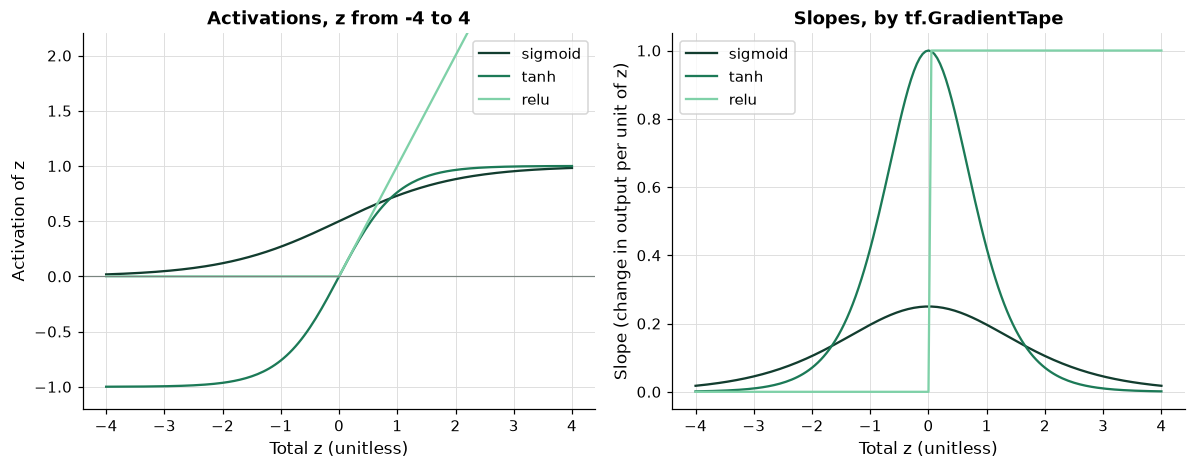

In [14]:
# plt was imported in the setup, with the course's chart style
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.4))
for name in ["sigmoid", "tanh", "relu"]:
    left.plot(z_grid.numpy(), curves[name], label=name)
    right.plot(z_grid.numpy(), slopes[name], label=name)
left.axhline(0, color=plotkit.GREY, linewidth=0.8)
left.set_ylim(-1.2, 2.2)
left.set_title("Activations, z from -4 to 4")
left.set_xlabel("Total z (unitless)")
left.set_ylabel("Activation of z")
left.legend()
right.set_title("Slopes, by tf.GradientTape")
right.set_xlabel("Total z (unitless)")
right.set_ylabel("Slope (change in output per unit of z)")
right.legend()
plt.tight_layout()
plt.show()

* Left: three ways to bend a straight total. Right: the sigmoid's slope is a low hump, tanh's a taller one, and ReLU's a step from 0 to 1.

### Softmax: more than two groups

**How it works.** A sigmoid output answers one question, default or not. When the answer is one of several groups, the output layer has one unit per group and each unit gives a score. **Softmax** turns the scores into probabilities that add to 1: raise e to each score, then divide each by the sum of all of them, so a higher score gets a larger share and no probability is negative. The loss for a row is minus the log of the probability given to its true group, written as a one-hot target times the log of the probabilities (Keras's `categorical_crossentropy`). You control the number of groups. What comes out is one probability per group. This course's networks have two groups, so they use one sigmoid; with two groups, softmax and the sigmoid are the same thing.

Q. Three invented scores for three repayment groups: current, one month late, two or more months late. Turn them into probabilities by hand and with Keras, and work out the loss for each possible true group.

                         score  e to the score  softmax
current                    2.0          7.3891   0.7054
one month late             1.0          2.7183   0.2595
two or more months late   -1.0          0.3679   0.0351
the probabilities add to 1.0; keras.activations.softmax equal within 1e-6: True
softmax of (1.3, 0): 0.785835; sigmoid of 1.3: 0.785835
loss if the second group is true: by hand 1.3490, Keras 1.3490; equal within 1e-6: True


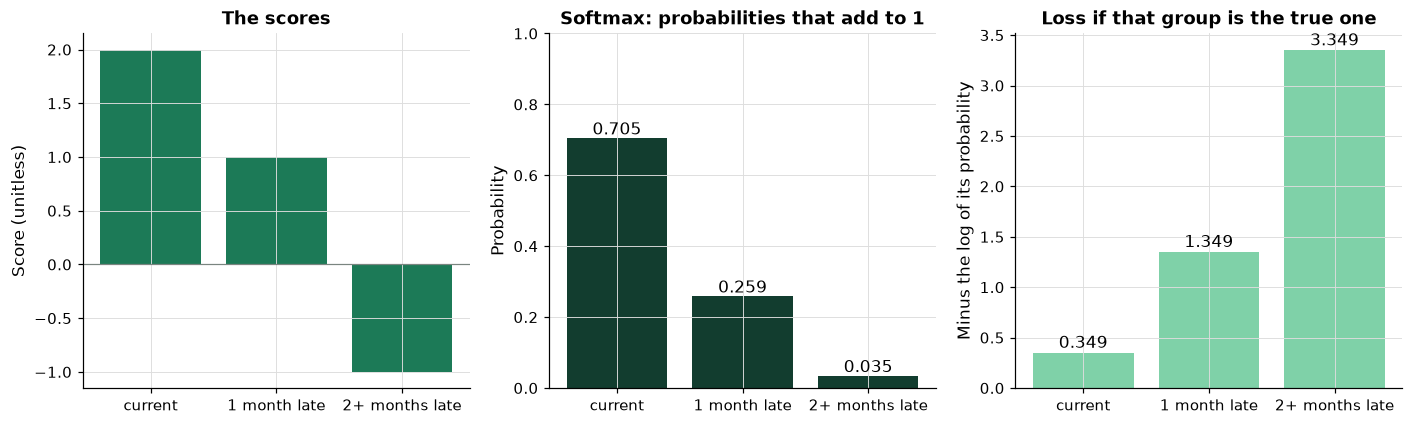

In [15]:
# three scores for the three groups (invented, to show the arithmetic)
groups = ["current", "one month late", "two or more months late"]
scores = np.array([2.0, 1.0, -1.0])
exp_scores = np.exp(scores)
softmax_hand = exp_scores / exp_scores.sum()
softmax_keras = keras.activations.softmax(tf.constant(scores[None, :], dtype=tf.float32)).numpy()[0]
print(pd.DataFrame({"score": scores, "e to the score": exp_scores, "softmax": softmax_hand}, index=groups).round(4).to_string())
print(f"the probabilities add to {softmax_hand.sum():.1f}; keras.activations.softmax equal within 1e-6: {np.abs(softmax_keras - softmax_hand).max() < 1e-6}")

# with two groups, softmax of (z, 0) is the sigmoid of z: day 2's neuron is a softmax with two groups
z_two = 1.3
two_group = np.exp([z_two, 0.0]) / np.exp([z_two, 0.0]).sum()
print(f"softmax of (1.3, 0): {two_group[0]:.6f}; sigmoid of 1.3: {1 / (1 + np.exp(-z_two)):.6f}")

# the loss when the true group is the second: a one-hot target times the log of the probabilities, negated
target = np.array([0.0, 1.0, 0.0])
loss_by_hand = -(target * np.log(softmax_hand)).sum()
loss_keras = float(keras.losses.categorical_crossentropy(tf.constant(target[None, :], dtype=tf.float32),
                                                        tf.constant(softmax_hand[None, :], dtype=tf.float32)).numpy()[0])
print(f"loss if the second group is true: by hand {loss_by_hand:.4f}, Keras {loss_keras:.4f}; equal within 1e-6: {abs(loss_by_hand - loss_keras) < 1e-6}")

fig, (left, middle, right) = plt.subplots(1, 3, figsize=(13, 4))
short = ["current", "1 month late", "2+ months late"]
left.bar(short, scores, color=plotkit.GREEN)
left.axhline(0, color=plotkit.GREY, linewidth=0.8)
left.set_title("The scores")
left.set_ylabel("Score (unitless)")
middle.bar(short, softmax_hand, color=plotkit.GREEN_DARK)
for position, value in enumerate(softmax_hand):
    middle.text(position, value + 0.01, f"{value:.3f}", ha="center")
middle.set_ylim(0, 1)
middle.set_title("Softmax: probabilities that add to 1")
middle.set_ylabel("Probability")
right.bar(short, -np.log(softmax_hand), color=plotkit.GREEN_LIGHT)
for position, value in enumerate(-np.log(softmax_hand)):
    right.text(position, value + 0.05, f"{value:.3f}", ha="center")
right.set_title("Loss if that group is the true one")
right.set_ylabel("Minus the log of its probability")
fig.tight_layout()
plt.show()

* The highest score, 2 for "current", gets 0.7054 of the probability, and the lowest, -1, gets 0.0351: softmax keeps the order of the scores and makes them add to 1. Nothing is left over, which is the difference from three separate sigmoids.
* The loss is small when the true group is the one the model scored highest (0.3490 for "current") and large when it is the one it scored lowest (3.3490): a confident miss costs most. This is day 1's log loss with more than two groups. The sigmoid check above shows why the course does not need softmax: with two groups it is the same function.

## 3.2 A Hidden Layer of Two Units, by Hand

**How it works.** One neuron draws one straight boundary through its inputs, and some patterns need more. A **hidden layer** is a row of units that all see the same inputs. Each has its own weights and intercept, so each computes its own total and its own activation, and each is a different view of the same row. The next layer treats those outputs as its inputs and combines them, which is what lets a network bend its boundary. You control the number of units (the width), their activation, and the number of layers (the depth). What comes out is one output per unit, passed on to the next layer. Nothing is fitted in this section: the weights are chosen by hand, so every number can be followed.

Two inputs, `PAY_0` and `LIMIT_BAL` (both scaled), two hidden units, one output:

| | weight on `PAY_0` | weight on `LIMIT_BAL` | intercept |
| --- | --- | --- | --- |
| hidden unit 1 | 1.2 | -0.3 | -0.2 |
| hidden unit 2 | 0.4 | -0.9 | 0.1 |

| | weight on unit 1 | weight on unit 2 | intercept |
| --- | --- | --- | --- |
| output | 1.5 | 0.8 | -1.6 |

Q. Build this network in Keras twice, once with ReLU hidden units and once with tanh, and give both these weights.

In [16]:
# the scaled PAY_0 and LIMIT_BAL columns of the fit rows
two_columns = [X_fit.columns.get_loc("PAY_0"), X_fit.columns.get_loc("LIMIT_BAL")]
A_two = A_fit[:, two_columns]

# Keras stores a layer's kernel as inputs by units: one row per input, one column per unit
hidden_kernel = np.array([[1.2, 0.4], [-0.3, -0.9]], dtype="float32")
hidden_bias = np.array([-0.2, 0.1], dtype="float32")
output_kernel = np.array([[1.5], [0.8]], dtype="float32")
output_bias = np.array([-1.6], dtype="float32")
weights = [hidden_kernel, hidden_bias, output_kernel, output_bias]

two_units = {}
for activation in ["relu", "tanh"]:
    # seed before building any Keras model, so its numbers never depend on what ran before
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(2,)), keras.layers.Dense(2, activation=activation, name="hidden"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name=f"two_units_{activation}")
    # replace the random starting weights with the chosen ones, in the order get_weights lists them
    model.set_weights(weights)
    two_units[activation] = model
    print(f"{model.name}: kernel shapes {[w.shape for w in model.get_weights()[::2]]}")

two_units_relu: kernel shapes [(2, 2), (2, 1)]
two_units_tanh: kernel shapes [(2, 2), (2, 1)]


* The hidden kernel is 2 by 2 (two inputs, two units) and the output kernel 2 by 1 (two hidden units, one output). The two networks differ only in the hidden layer's activation.

Q. Compute both networks' outputs by hand with numpy, show the first five fit rows, and compare with `model.predict` on all the fit rows.

In [17]:
# float64 copies of the weights and the inputs, for the hand calculation
k, b, v, c = (w.astype("float64") for w in weights)
rows = A_two.astype("float64")

# each hidden unit: its total, then its activation; rows @ k gives both units' totals at once
relu_hidden = np.maximum(0.0, rows @ k + b)
tanh_hidden = np.tanh(rows @ k + b)
# the output neuron: a total of the hidden outputs, then the sigmoid
relu_output = 1 / (1 + np.exp(-(relu_hidden @ v + c)))[:, 0]
tanh_output = 1 / (1 + np.exp(-(tanh_hidden @ v + c)))[:, 0]

first = pd.DataFrame({"PAY_0": rows[:5, 0], "LIMIT_BAL": rows[:5, 1], "relu unit 1": relu_hidden[:5, 0],
                      "relu unit 2": relu_hidden[:5, 1], "relu output": relu_output[:5], "tanh output": tanh_output[:5]})
print(first.round(4).to_string(index=False))
for activation, by_hand in [("relu", relu_output), ("tanh", tanh_output)]:
    keras_output = two_units[activation].predict(A_two, verbose=0)[:, 0]
    print(f"{activation}: hand output equal to model.predict within 1e-6 on all {len(rows):,} fit rows: "
          f"{np.abs(keras_output - by_hand).max() < 1e-6}")
print(f"fit rows where a ReLU unit outputs exactly 0: {(relu_hidden == 0).any(axis=1).sum():,}")

  PAY_0  LIMIT_BAL  relu unit 1  relu unit 2  relu output  tanh output
 1.8078    -1.0596       2.2873       1.7768       0.9628       0.6513
-0.8841    -1.1372       0.0000       0.7699       0.2721       0.1024
 1.8078    -0.3612       2.0777       1.1482       0.9195       0.6242
-0.8841     0.2595       0.0000       0.0000       0.1680       0.0367
 0.9105     1.0355       0.5820       0.0000       0.3258       0.2381


relu: hand output equal to model.predict within 1e-6 on all 14,400 fit rows: True


tanh: hand output equal to model.predict within 1e-6 on all 14,400 fit rows: True
fit rows where a ReLU unit outputs exactly 0: 8,680


* Follow the first row: its scaled `PAY_0` is 1.8078 (a raw `PAY_0` of 2) and its scaled limit -1.0596. Unit 1's total is 1.2 x 1.8078 + (-0.3) x (-1.0596) + (-0.2) = 2.2873, positive, so ReLU passes it. The output neuron adds up 1.5 times unit 1 and 0.8 times unit 2, plus -1.6, and takes the sigmoid: 0.9628.
* The second row's unit 1 has a negative total, so its ReLU output is 0: that unit says nothing about the row. 8,680 of the 14,400 fit rows have at least one silent ReLU unit (40.5 percent for unit 2 alone). A tanh unit is never silent, which is why the two networks' outputs differ row by row.
* numpy in float64 and Keras in float32 agree within 1e-6 on every fit row. A network is these few lines, repeated per layer.

## 3.3 `forward_pass`: The Output Layer by Layer

**How it works.** A network's output is made by passing the inputs through its layers in order. Every `Dense` layer does the same two lines: multiply the inputs by its kernel and add its bias, which gives a total for each unit, then put each total through the layer's activation. One layer's output is the next layer's input, and the last layer's output is the network's output. This is the **forward pass**; day 1's tape walks the same layers backward to get the gradients. You control nothing: the weights and the activations fix it. What comes out is every layer's output, and the last one is what `model.predict` returns. A function can walk any stack of `Dense` layers that way, read each layer's activation from Keras, and check it.

Q. Add `forward_pass` to `netkit.py`. Read the docstring first.

In [18]:
%%writefile -a netkit.py


ACTIVATIONS = {
    "linear": lambda z: z,
    "relu": lambda z: np.maximum(0.0, z),
    "tanh": np.tanh,
    "sigmoid": lambda z: 1 / (1 + np.exp(-z)),
}


def forward_pass(model, A) -> np.ndarray:
    """A dense network's output computed with numpy, layer by layer, in float64.

    Inputs: model, a Keras Sequential model of Dense layers (activations linear, relu, tanh, or sigmoid) and
    Dropout layers; A, the scaled input rows (rows by inputs).
    Output: the model's output for each row, shaped as model.predict's (rows by output units). Each Dense layer
    computes activation(inputs @ kernel + bias); Dropout passes its inputs through, as at scoring time.
    Convention: equals model.predict(A, verbose=0) within 1e-5 (Keras computes in float32).
    Excel: one unit is =MAX(0,SUMPRODUCT(inputs,weights)+bias) for ReLU, =TANH(...) for tanh,
    =1/(1+EXP(-(...))) for sigmoid.
    Raises ValueError on any other layer or activation, or rows of the wrong width.
    """
    values = np.asarray(A, dtype=float)
    if values.ndim != 2 or values.shape[0] == 0:
        raise ValueError(f"A must be a non-empty 2-D array of rows by inputs, not shape {values.shape}")
    for layer in model.layers:
        if isinstance(layer, keras.layers.Dropout):
            continue  # at scoring time dropout changes nothing
        if not isinstance(layer, keras.layers.Dense):
            raise ValueError(f"forward_pass handles Dense and Dropout layers only, not {type(layer).__name__}")
        activation = layer.get_config()["activation"]
        if activation not in ACTIVATIONS:
            raise ValueError(f"forward_pass handles {sorted(ACTIVATIONS)} activations only, not {activation!r}")
        kernel, bias = (w.astype(float) for w in layer.get_weights())
        if values.shape[1] != kernel.shape[0]:
            raise ValueError(f"layer {layer.name} expects {kernel.shape[0]} inputs, not {values.shape[1]}")
        values = ACTIVATIONS[activation](values @ kernel + bias)
    return values

Appending to netkit.py


* `ACTIVATIONS` maps the name Keras stores for each activation to its numpy formula. `"linear"` is what Keras stores when a `Dense` layer is given no activation: the total itself (section 3.6).
* `layer.get_config()["activation"]` reads a layer's activation by name, and `layer.get_weights()` returns its kernel and its intercepts (Keras names them the bias).
* `Dropout` passes its inputs through: at scoring time it does nothing (day 9). Any other layer stops the function with `ValueError`, rather than returning a number that ignores it.

Q. Add three tests: agreement with `model.predict`, a network with dropout, and the refusal.

In [19]:
%%writefile -a test_netkit.py


def small_network(n_inputs: int = 3, dropout: float = 0.0) -> keras.Model:
    """A seeded 8-4 network with tanh and ReLU hidden layers and a sigmoid output, compiled."""
    keras.utils.set_random_seed(SEED)
    layers = [keras.Input(shape=(n_inputs,)), keras.layers.Dense(8, activation="tanh", name="hidden_1")]
    if dropout:
        layers.append(keras.layers.Dropout(dropout, name="dropout_1"))
    layers += [keras.layers.Dense(4, activation="relu", name="hidden_2"),
               keras.layers.Dense(1, activation="sigmoid", name="output")]
    model = keras.Sequential(layers, name="small_network")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy")
    return model


def test_forward_pass_matches_predict():
    X, _ = small_rows(50)
    model = small_network()
    expected = model.predict(X.astype("float32"), verbose=0)
    by_hand = netkit.forward_pass(model, X.astype("float32"))
    assert by_hand.shape == expected.shape == (50, 1)
    assert np.allclose(by_hand, expected, rtol=0, atol=1e-5)


def test_forward_pass_skips_dropout():
    X, _ = small_rows(50)
    model = small_network(dropout=0.5)
    assert np.allclose(netkit.forward_pass(model, X), model.predict(X.astype("float32"), verbose=0), rtol=0, atol=1e-5)


def test_forward_pass_rejects_other_layers():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(3,)), keras.layers.BatchNormalization(name="batch_norm"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="with_batch_norm")
    X, _ = small_rows(10)
    with pytest.raises(ValueError):
        netkit.forward_pass(model, X)

Appending to test_netkit.py


* `small_network` is a seeded 8-4 network on three inputs, with a tanh layer and a ReLU layer, so one test covers two activations. The refusal test gives `forward_pass` a batch normalization layer (day 8), which it does not handle.

Q. Reload `netkit` and run the tests.

In [20]:
# the file changed, so reload before using the new function
importlib.reload(netkit)
print(f"forward_pass in netkit: {hasattr(netkit, 'forward_pass')}")

forward_pass in netkit: True


In [21]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_netkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.............                                                            [100%]
13 passed in 7.22s



* `13 passed`: day 2's 10 and the three new ones.

Q. Does `forward_pass` reproduce both two-unit networks?

In [22]:
for activation, by_hand in [("relu", relu_output), ("tanh", tanh_output)]:
    by_function = netkit.forward_pass(two_units[activation], A_two)[:, 0]
    keras_output = two_units[activation].predict(A_two, verbose=0)[:, 0]
    print(f"{activation}: forward_pass equal to the hand calculation within 1e-12: {np.abs(by_function - by_hand).max() < 1e-12}; "
          f"to model.predict within 1e-5: {np.abs(by_function - keras_output).max() < 1e-5}")

relu: forward_pass equal to the hand calculation within 1e-12: True; to model.predict within 1e-5: True


tanh: forward_pass equal to the hand calculation within 1e-12: True; to model.predict within 1e-5: True


* `forward_pass` is the hand calculation, to the last digit, and it agrees with Keras within the 1e-5 its docstring promises (the gaps are float32's). From now on `forward_pass` can check any dense network in the course.

## 3.4 Counting Parameters

**How it works.** The parameters are the numbers fitting can change, so their count measures how flexible a network is and how much it can memorise. A `Dense` layer from a inputs to b units has a weight for every input and unit pair, a x b of them, and one intercept per unit, b: a x b + b **parameters**. A network's count is the sum over its layers. You control the widths and the depth, and the count follows; a wider layer costs the product of its neighbours' widths, so parameters grow faster than units. What comes out is one whole number, read from `count_params()` and worked by hand.

The two-unit network has 2 x 2 + 2 = 6 in its hidden layer and 2 x 1 + 1 = 3 in its output: 9.

Q. Add `parameter_count` and its two tests, reload, and run all of today's tests.

In [23]:
%%writefile -a netkit.py


def parameter_count(layer_sizes: list[int]) -> int:
    """How many weights and biases a stack of dense layers has.

    Input: layer_sizes, the number of inputs first, then each layer's units, the output layer last, for example
    [19, 64, 32, 1].
    Output: the sum of a * b + b over consecutive sizes a, b (a kernel of a by b weights and b biases per layer).
    Convention: equals model.count_params() for a Sequential model of Dense layers.
    Excel: =19*64+64 for one layer, added up over the layers.
    Raises ValueError on fewer than two sizes or a size below 1.
    """
    sizes = list(layer_sizes)
    if len(sizes) < 2 or min(sizes) < 1:
        raise ValueError(f"need at least two sizes, each at least 1, not {sizes}")
    return int(sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:])))

Appending to netkit.py


In [24]:
%%writefile -a test_netkit.py


def test_parameter_count_matches_keras():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(19,)), keras.layers.Dense(64, activation="relu", name="hidden_1"),
                              keras.layers.Dense(32, activation="relu", name="hidden_2"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="card_network")
    assert netkit.parameter_count([19, 64, 32, 1]) == model.count_params() == 3_393
    # by hand: 19 * 16 + 16 = 320 and 16 * 1 + 1 = 17
    assert netkit.parameter_count([19, 16, 1]) == 337


def test_parameter_count_rejects_short_list():
    with pytest.raises(ValueError):
        netkit.parameter_count([19])
    with pytest.raises(ValueError):
        netkit.parameter_count([19, 0, 1])

Appending to test_netkit.py


In [25]:
importlib.reload(netkit)
print(f"parameter_count in netkit: {hasattr(netkit, 'parameter_count')}")

parameter_count in netkit: True


In [26]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_netkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...............                                                          [100%]
15 passed in 6.93s



* `15 passed`: today's two functions, tested. The test writes one count out by hand in a comment, 19 x 16 + 16 = 320 and 16 x 1 + 1 = 17, so 337.

Q. Write one function that builds every network of today's ladder, seeded, so the next sections change one setting at a time and nothing else.

In [27]:
def build_network(units, activation, name):
    """A seeded, compiled network: one Dense layer per entry of units, then a sigmoid output."""
    # seed before building any Keras model, so its numbers never depend on what ran before
    keras.utils.set_random_seed(SEED)
    layers = [keras.Input(shape=(n_inputs,))]
    for number, size in enumerate(units, start=1):
        layers.append(keras.layers.Dense(size, activation=activation, name=f"hidden_{number}"))
    layers.append(keras.layers.Dense(1, activation="sigmoid", name="output"))
    model = keras.Sequential(layers, name=name)
    # Adam at Keras's default learning rate, and the mean log loss
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy")
    return model


# the ladder: the hidden layers, their activation, the model's name, and a description
ladder_plan = [((), None, "model_0", "one neuron"), ((16,), "sigmoid", "model_1", "16 sigmoid units"),
               ((16,), "tanh", "model_2", "16 tanh units"), ((16,), "relu", "model_3", "16 ReLU units"),
               ((32,), "relu", "model_4", "32 ReLU units"), ((32, 16), "relu", "model_5", "32 and 16 ReLU units")]
for units, activation, name, description in ladder_plan:
    sizes = [n_inputs, *units, 1]
    print(f"{name}, {description}: sizes {sizes}, parameter_count {netkit.parameter_count(sizes):,}, "
          f"count_params {build_network(units, activation, name).count_params():,}")

model_0, one neuron: sizes [19, 1], parameter_count 20, count_params 20
model_1, 16 sigmoid units: sizes [19, 16, 1], parameter_count 337, count_params 337
model_2, 16 tanh units: sizes [19, 16, 1], parameter_count 337, count_params 337
model_3, 16 ReLU units: sizes [19, 16, 1], parameter_count 337, count_params 337
model_4, 32 ReLU units: sizes [19, 32, 1], parameter_count 673, count_params 673
model_5, 32 and 16 ReLU units: sizes [19, 32, 16, 1], parameter_count 1,185, count_params 1,185


* Model 0 has 20 parameters (19 weights and an intercept: day 2's neuron). One hidden layer of 16 takes it to 337, 32 units to 673, and a second layer of 16 to 1,185. Each count is `parameter_count`'s and Keras's alike.
* With no hidden layer, `units` is empty and the loop adds nothing: the same function builds the neuron.

Q. Show Keras's own table for Model 5 with `model.summary()`.

In [28]:
# print_fn=print sends the table to the cell's printed output as plain text
build_network((32, 16), "relu", "model_5").summary(print_fn=print)

Model: "model_5"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 32)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 1,185 (4.63 KB)
 Trainable params: 1,185 (4.63 KB)
 Non-trainable params: 0 (0.00 B)



* One row per layer, with its output shape and its parameters: 640 = 19 x 32 + 32, 528 = 32 x 16 + 16, and 17 = 16 x 1 + 1, 1,185 in all. The output shape `(None, 32)` means any number of rows by 32 units: Keras leaves the row count open. The size in KB is the parameters in float32, 4 bytes each.
* The course shows `model.summary()` here once. Elsewhere it counts with `parameter_count` and `count_params()`, which print one number.

## 3.5 The Ladder: One Setting at a Time

**How it works.** Which network fits best is not known in advance, and changing several settings at once leaves no clue about which one mattered. A **ladder** changes one setting at a time from a starting model, so each rung's difference has one explanation. Every model is fitted the same way on the fit rows and scored on rows it was not fitted on, by the loss it was fitted to lower. You control the starting model, the order of the rungs, and the rule for choosing. What comes out is a table of models with one loss each, and a choice made on the stopping rows.

The choice is made on rows the report never sees: the 3,600 **stopping rows**. The rule for the ladder is Course 5's: **change one setting at a time**, so each difference has one explanation. Every model is fitted on the 14,400 fit rows for 20 epochs at batch 64 (225 steps an epoch; day 4 takes epochs and batches apart) and scored by its **mean log loss on the stopping rows**, the loss the network was fitted to lower, on rows it was not fitted on. The fit rows' loss is shown beside it.

Q. Write the function that fits a model and scores it, then fit Model 0, the neuron.

In [29]:
# each model's Keras history, by name: loss on the fit rows and val_loss on the stopping rows, epoch by epoch
curves = {}


def fit_and_score(model, description):
    """Fit on the fit rows for 20 epochs at batch 64; the mean log loss on the fit and stopping rows."""
    # validation_data (day 2) scores the stopping rows after every epoch; it only reads them, the steps use the fit rows
    history = model.fit(A_fit, y_fit_array, epochs=20, batch_size=64,
                        validation_data=(A_stop, y_stop.to_numpy("float32")), verbose=0)
    curves[model.name] = history.history
    return {"model": model.name, "layers": description, "parameters": model.count_params(),
            "fit loss": netkit.mean_log_loss(y_fit, model.predict(A_fit, verbose=0)[:, 0]),
            "stopping loss": netkit.mean_log_loss(y_stop, model.predict(A_stop, verbose=0)[:, 0])}


def show(result):
    print(f"{result['model']}, {result['layers']}: {result['parameters']:,} parameters, "
          f"fit loss {result['fit loss']:.4f}, stopping loss {result['stopping loss']:.4f}")


models, ladder = {}, []
models["model_0"] = build_network((), None, "model_0")
ladder.append(fit_and_score(models["model_0"], "one neuron"))
show(ladder[-1])

model_0, one neuron: 20 parameters, fit loss 0.4617, stopping loss 0.4702


**Rows.** Every network on the card file in this notebook is fitted on Course 4's 18,000 training rows (14,400 to fit and 3,600 to stop or choose) and scored on Course 4's 6,000 validation rows; Course 4's 6,000 test rows are never scored in this course.

* Model 0's stopping loss is 0.4702. It is day 2's neuron fitted the ladder's way (Adam at 0.001, 20 epochs, batch 64), so every rung starts from the same footing. Its fit loss, 0.4617, is a little lower: rows a model was fitted on usually score a little better.
* `validation_data` is day 2's: after every epoch Keras scores the stopping rows and stores the result as `val_loss`. `fit_and_score` keeps each model's history in `curves`, for a chart once the ladder is built. The weights are the same as without it.

Q. Model 1: put a hidden layer of 16 sigmoid units in front of the output.

In [30]:
models["model_1"] = build_network((16,), 'sigmoid', "model_1")
ladder.append(fit_and_score(models["model_1"], "16 sigmoid units"))
show(ladder[-1])

model_1, 16 sigmoid units: 337 parameters, fit loss 0.4380, stopping loss 0.4496


* 0.4496 against 0.4702: one hidden layer lowers the stopping loss by 0.0206, the largest step of the day. The network can now bend where the neuron could only draw a straight line.
* One setting changed from Model 0: a hidden layer of 16 sigmoid units; chosen on the 3,600 stopping rows.

Q. Model 2: 16 tanh units.

In [31]:
models["model_2"] = build_network((16,), 'tanh', "model_2")
ladder.append(fit_and_score(models["model_2"], "16 tanh units"))
show(ladder[-1])

model_2, 16 tanh units: 337 parameters, fit loss 0.4253, stopping loss 0.4427


* 0.4427: tanh, with its steeper slope, does better than the sigmoid on the same 16 units.
* One setting changed from Model 1: the activation, sigmoid to tanh; chosen on the 3,600 stopping rows.

Q. Model 3: 16 ReLU units.

In [32]:
models["model_3"] = build_network((16,), 'relu', "model_3")
ladder.append(fit_and_score(models["model_3"], "16 ReLU units"))
show(ladder[-1])

model_3, 16 ReLU units: 337 parameters, fit loss 0.4288, stopping loss 0.4449


* 0.4449: ReLU is 0.0022 behind tanh here. ReLU is the most common choice for hidden layers, and it is what the rest of the ladder uses, but on these rows, at 20 epochs, tanh's stopping loss is lower.
* One setting changed from Model 2: the activation, tanh to ReLU; chosen on the 3,600 stopping rows.

Q. Model 4: 32 ReLU units.

In [33]:
models["model_4"] = build_network((32,), 'relu', "model_4")
ladder.append(fit_and_score(models["model_4"], "32 ReLU units"))
show(ladder[-1])

model_4, 32 ReLU units: 673 parameters, fit loss 0.4256, stopping loss 0.4442


* 0.4442: twice the units, 673 parameters, and a little lower than Model 3.
* One setting changed from Model 3: the width, 16 ReLU units to 32; chosen on the 3,600 stopping rows.

Q. Model 5: 32 and 16 ReLU units.

In [34]:
models["model_5"] = build_network((32, 16), 'relu', "model_5")
ladder.append(fit_and_score(models["model_5"], "32 and 16 ReLU units"))
show(ladder[-1])

model_5, 32 and 16 ReLU units: 1,185 parameters, fit loss 0.4199, stopping loss 0.4448


* 0.4448: a second layer lowers the fit loss to 0.4199, the lowest of the ladder, but not the stopping loss, which ends a little above Model 4's.
* One setting changed from Model 4: the depth, a second hidden layer of 16 ReLU units; chosen on the 3,600 stopping rows.

Q. Put the whole ladder in one table.

In [35]:
ladder_table = pd.DataFrame(ladder).set_index("model")
chosen = ladder_table["stopping loss"].drop("model_0").idxmin()
print(f"lowest stopping loss among the networks with a hidden layer: {chosen}")
# the stopping loss is the column the rule reads, so it is the one marked (lowest is best)
plotkit.styled(ladder_table, ["stopping loss"],
               "The ladder: mean log loss after 20 epochs at batch 64, fitted on the 14,400 fit rows; the rule reads the 3,600 stopping rows",
               higher_is_better=False, fmt="{:.4f}")

lowest stopping loss among the networks with a hidden layer: model_2


,layers,parameters,fit loss,stopping loss
model,,,,
model_0,one neuron,20,0.4617,0.4702
model_1,16 sigmoid units,337,0.4380,0.4496
model_2,16 tanh units,337,0.4253,0.4427
model_3,16 ReLU units,337,0.4288,0.4449
model_4,32 ReLU units,673,0.4256,0.4442
model_5,32 and 16 ReLU units,"1,185",0.4199,0.4448


* Every hidden layer beats the neuron by about 0.0206 or more. Among Models 2 to 5 the stopping losses lie within 0.0022 of each other, less than a fifth of that first step.
* The rule chooses **Model 2, 16 tanh units**, the lowest stopping loss (marked). Differences of a few ten-thousandths are the size a different seed alone can move (day 4 measures that spread), so this choice is the rule's, not proof that tanh is better on this file. Day 5 starts its own ladder from here and measures more carefully.

Q. Draw each model's mean log loss on the stopping rows after every epoch, one line per model, from the histories in `curves`.

val_loss at epoch 20 equal to fit_and_score's stopping loss to 4 decimals, every model: True


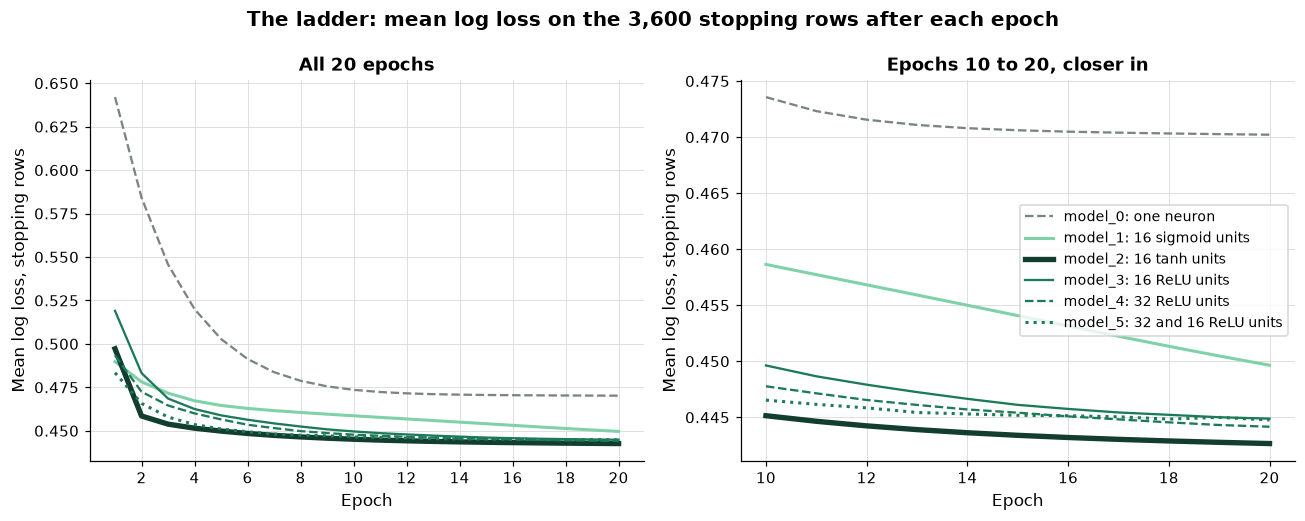

In [36]:
# the stopping rows' mean log loss after each epoch (Keras's val_loss), one column per model of the ladder
stopping_curves = pd.DataFrame({name: curves[name]["val_loss"] for name in ladder_table.index},
                               index=pd.RangeIndex(1, 21, name="Epoch"))
same = all(round(stopping_curves[name].iloc[-1], 4) == round(ladder_table.loc[name, "stopping loss"], 4)
           for name in ladder_table.index)
print(f"val_loss at epoch 20 equal to fit_and_score's stopping loss to 4 decimals, every model: {same}")

# colour, line style, and width per model: grey for the neuron, a green per activation, the ReLU models by line style
looks = {"model_0": (plotkit.GREY, "--", 1.5), "model_1": (plotkit.GREEN_LIGHT, "-", 2),
         "model_2": (plotkit.GREEN_DARK, "-", 3.5), "model_3": (plotkit.GREEN, "-", 1.5),
         "model_4": (plotkit.GREEN, "--", 1.5), "model_5": (plotkit.GREEN, ":", 2)}
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.8))
for name in stopping_curves.columns:
    colour, line, width = looks[name]
    label = f"{name}: {ladder_table.loc[name, 'layers']}"
    left.plot(stopping_curves.index, stopping_curves[name], color=colour, linestyle=line, linewidth=width, label=label)
    # the right panel starts at epoch 10, so the five networks with a hidden layer can be told apart
    later = stopping_curves.loc[10:, name]
    right.plot(later.index, later, color=colour, linestyle=line, linewidth=width, label=label)
left.set_title("All 20 epochs")
right.set_title("Epochs 10 to 20, closer in")
for ax in (left, right):
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean log loss, stopping rows")
left.set_xticks(range(2, 21, 2))
right.set_xticks(range(10, 21, 2))
right.legend(fontsize=9, loc="center right")
fig.suptitle("The ladder: mean log loss on the 3,600 stopping rows after each epoch", fontweight="bold")
fig.tight_layout()
plt.show()

* Left: Model 0, the dashed grey line, starts at 0.6420 after one epoch and needs 13 epochs to come within 0.001 of where it ends. Every model with a hidden layer is below it at every epoch.
* Right: Model 2's thick line is the lowest from epoch 2 to epoch 20, so the rule's choice is not an accident of the last epoch. The three ReLU models (green, solid, dashed, dotted) bunch just above it, and Model 1's sigmoid line sits above them from epoch 10 on.
* Model 1 is still falling 0.0008 an epoch at epoch 20, more than three times as fast as Models 2 to 5 (at most 0.0002). Section 3.1's slopes are one likely reason: a sigmoid unit's slope is never more than 0.25, so its weights move in small steps.
* Every line is at its lowest at epoch 20, the last. Twenty epochs is a setting of the ladder, not the point where any model stopped improving; day 4 measures how many a network needs.

Q. Draw what each rung costs and what it buys: the parameters and the stopping loss per model.

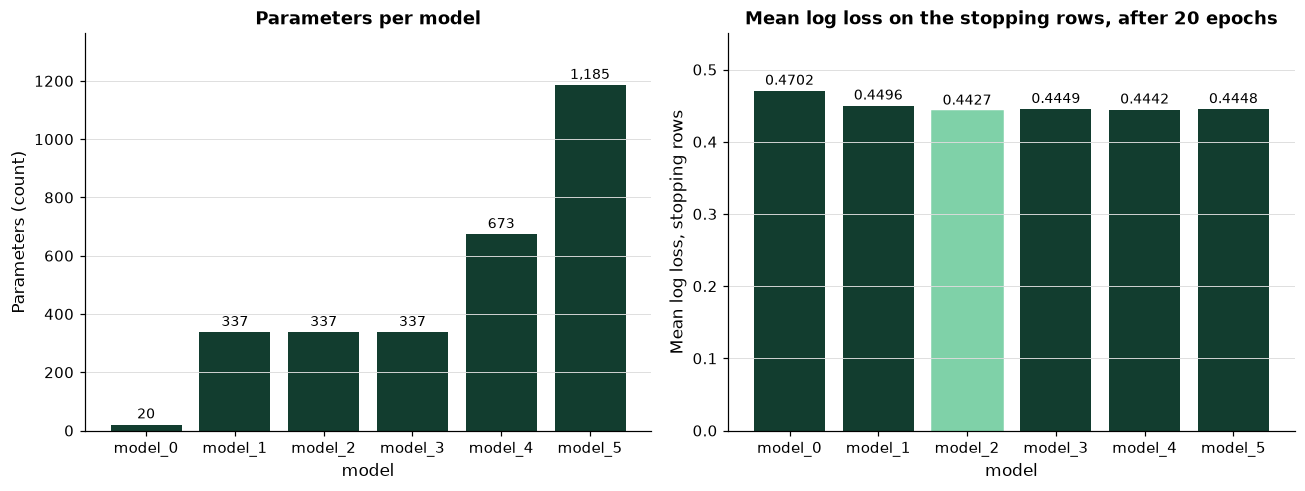

In [37]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.6))
plotkit.bars(ladder_table[["parameters"]], "Parameters per model", "Parameters (count)", ax=left, fmt="{:,.0f}")
# plotkit.bars leaves no room above the tallest label, so each panel gets its own y limit
left.set_ylim(0, 1.15 * ladder_table["parameters"].max())
plotkit.bars(ladder_table[["stopping loss"]], "Mean log loss on the stopping rows, after 20 epochs",
             "Mean log loss, stopping rows", ax=right, fmt="{:.4f}")
right.set_ylim(0, 0.55)
# the chosen model's bar in the light green
right.patches[list(ladder_table.index).index(chosen)].set_color(plotkit.GREEN_LIGHT)
fig.tight_layout()
plt.show()

* Left: from 20 parameters to 1,185, about 59 times as many. Right, with the bars drawn from zero: Model 0's 0.4702 stands out, and Models 2 to 5 cannot be told apart by eye. The chosen Model 2 (light green) has 337 parameters; past the first hidden layer, more parameters bought nothing on these rows.

## 3.6 A `Dense` Layer Has No Activation Unless You Give It One

`keras.layers.Dense(32)` with no `activation=` is a **linear** layer: its output is the total, unbent. Stack two of them and each output is a straight-line combination of a straight-line combination of the inputs, which is itself one straight line. So a stack of linear layers in front of a sigmoid output is one neuron, however many parameters it has.

Q. Build Model 5's shape, 32 and 16 units, with no activation on the hidden layers. Fit it as the ladder did. How does it compare with Model 0?

In [38]:
models["linear_stack"] = build_network((32, 16), None, "linear_stack")
print(f"activations: {[layer.get_config()['activation'] for layer in models['linear_stack'].layers]}")
linear = fit_and_score(models["linear_stack"], "32 and 16 units, no activation")
show(linear)
show(ladder[0])

activations: ['linear', 'linear', 'sigmoid']


linear_stack, 32 and 16 units, no activation: 1,185 parameters, fit loss 0.4626, stopping loss 0.4702
model_0, one neuron: 20 parameters, fit loss 0.4617, stopping loss 0.4702


* 1,185 parameters, and a stopping loss of 0.4702: Model 0's 0.4702 to four decimals. The fit losses differ by 0.0009, because the two took different paths to the same kind of answer in 20 epochs.

Q. Prove the stack is one neuron: multiply its three kernels into one column of 19 weights, carry the intercepts through, and compare that neuron's output with the stack's.

In [39]:
# each layer's kernel and intercepts, in float64
(k1, b1), (k2, b2), (k3, b3) = ([w.astype("float64") for w in layer.get_weights()] for layer in models["linear_stack"].layers)
# (x @ k1 + b1) @ k2 + b2, then @ k3 + b3, multiplied out: one weight per input and one intercept
w_one = k1 @ k2 @ k3
b_one = (b1 @ k2 + b2) @ k3 + b3
one_neuron = 1 / (1 + np.exp(-(A_stop.astype("float64") @ w_one + b_one)))[:, 0]
stack = models["linear_stack"].predict(A_stop, verbose=0)[:, 0]
print(f"the stack's kernels {k1.shape}, {k2.shape}, {k3.shape} multiply out to {w_one.shape}")
print(f"one neuron equal to the {models['linear_stack'].count_params():,}-parameter stack within 1e-5 on the stopping rows: "
      f"{np.abs(one_neuron - stack).max() < 1e-5}")

the stack's kernels (19, 32), (32, 16), (16, 1) multiply out to (19, 1)
one neuron equal to the 1,185-parameter stack within 1e-5 on the stopping rows: True


* The 19 by 32, 32 by 16, and 16 by 1 kernels multiply out to 19 by 1: one weight per input. The stack's outputs are that neuron's outputs on every stopping row. The extra layers added parameters and no shape at all.
* The activation is what makes a hidden layer worth having. A `Dense` layer is linear unless it is given one, and Keras does not warn you. The AI check comes back to this.

Q. Draw both facts: the stack's output against its one neuron's on every stopping row, and the stack's stopping loss by epoch beside Model 0's.

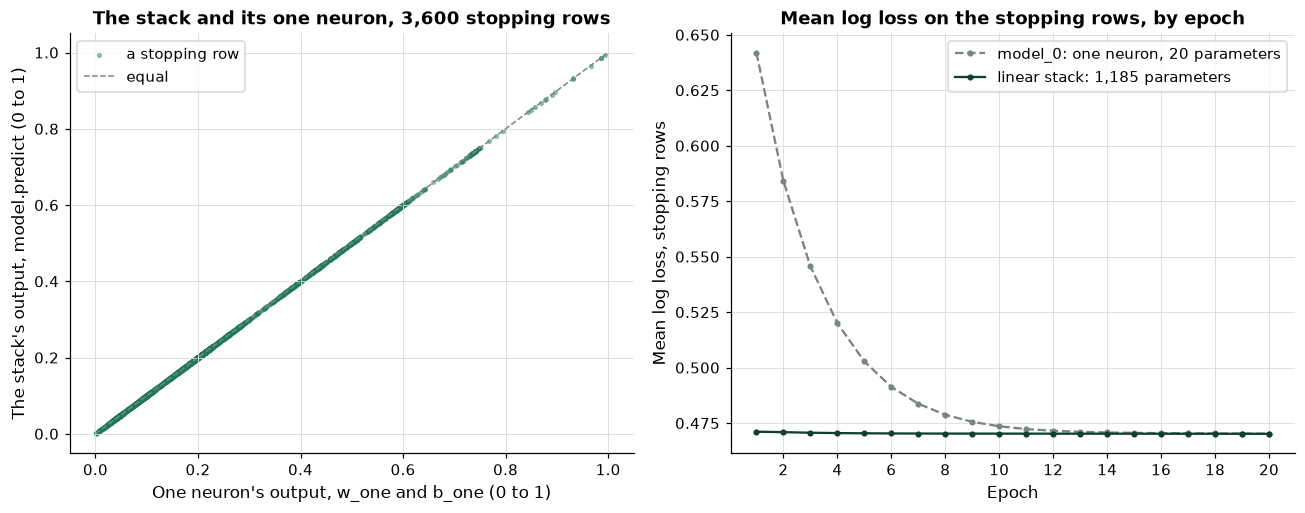

In [40]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.8))
left.scatter(one_neuron, stack, s=6, alpha=0.4, color=plotkit.GREEN, label="a stopping row")
left.plot([0, 1], [0, 1], color=plotkit.GREY, linestyle="--", linewidth=1, label="equal")
left.set_title("The stack and its one neuron, 3,600 stopping rows")
left.set_xlabel("One neuron's output, w_one and b_one (0 to 1)")
left.set_ylabel("The stack's output, model.predict (0 to 1)")
left.legend(loc="upper left")
epochs = range(1, 21)
right.plot(epochs, curves["model_0"]["val_loss"], color=plotkit.GREY, linestyle="--", marker="o", markersize=3,
           label="model_0: one neuron, 20 parameters")
right.plot(epochs, curves["linear_stack"]["val_loss"], color=plotkit.GREEN_DARK, marker="o", markersize=3,
           label="linear stack: 1,185 parameters")
right.set_title("Mean log loss on the stopping rows, by epoch")
right.set_xlabel("Epoch")
right.set_ylabel("Mean log loss, stopping rows")
right.set_xticks(range(2, 21, 2))
right.legend()
fig.tight_layout()
plt.show()

* Left: every dot lies on the line; the largest gap between the two outputs is 1.7e-07, float32's rounding.
* Right: the stack starts at 0.4711 after one epoch, where Model 0 starts at 0.6420, and both end at 0.4702. The extra parameters changed how fast the stack got there, not where it ended.

## 3.7 Width and Depth on This File

Width is how many units a layer has; depth is how many hidden layers. Models 3, 4, and 5 change one, then the other.

Q. Compare the fit loss and the stopping loss of Models 3 to 5, and the gap between them.

In [41]:
width_depth = ladder_table.loc[["model_3", "model_4", "model_5"], ["layers", "parameters", "fit loss", "stopping loss"]].copy()
width_depth["gap"] = width_depth["stopping loss"] - width_depth["fit loss"]
# lower is better in all three columns; each column marks its own lowest value
plotkit.styled(width_depth, ["fit loss", "stopping loss", "gap"],
               "Width and depth: Models 3 to 5 after 20 epochs, mean log loss on the fit rows and the stopping rows",
               higher_is_better=False, fmt="{:.4f}")

,layers,parameters,fit loss,stopping loss,gap
model,,,,,
model_3,16 ReLU units,337,0.4288,0.4449,0.0161
model_4,32 ReLU units,673,0.4256,0.4442,0.0185
model_5,32 and 16 ReLU units,"1,185",0.4199,0.4448,0.0249


* More parameters fit the fit rows better every time: 0.4288, 0.4256, 0.4199. The stopping rows gain less: 0.4449, 0.4442, then back up to 0.4448.
* The gap between the two losses widens from 0.0161 to 0.0185 to 0.0249. A model that improves on the rows it was fitted on faster than on the rows it was not is starting to fit the fit rows' accidents. That is the start of overfitting, the subject of day 9, and the reason choices are made on the stopping rows.
* The marks fall on three different rows: the lowest fit loss is Model 5's, the lowest stopping loss Model 4's, the smallest gap Model 3's.
* On this file, at 20 epochs, width helped a little and depth did not. That is a measured fact about these rows and these settings, not a rule about networks.

Q. Draw the ladder: fit loss and stopping loss for every model, the linear stack included.

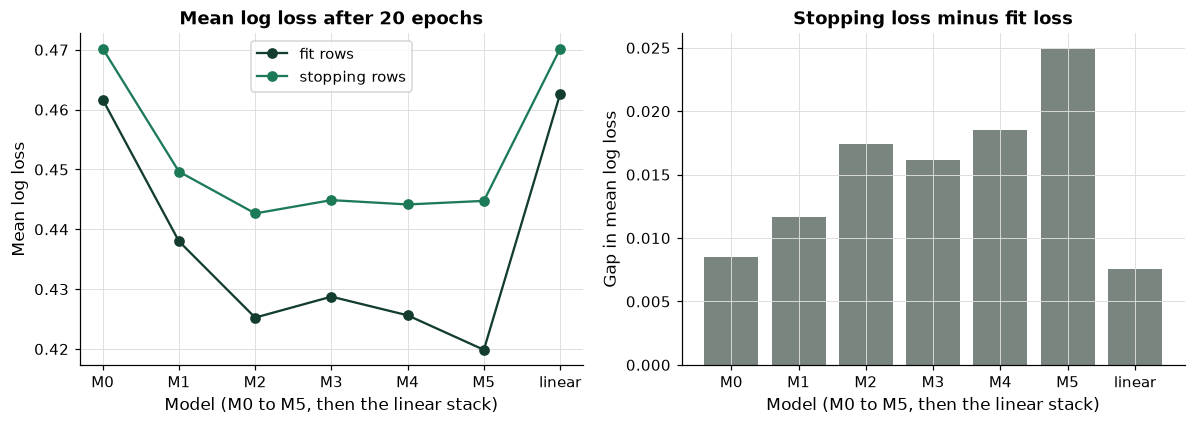

In [42]:
everything = pd.concat([ladder_table, pd.DataFrame([linear]).set_index("model")])
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
positions = np.arange(len(everything))
left.plot(positions, everything["fit loss"], marker="o", label="fit rows")
left.plot(positions, everything["stopping loss"], marker="o", label="stopping rows")
left.set_xticks(positions, [name.replace("model_", "M") if name.startswith("model") else "linear" for name in everything.index])
left.set_title("Mean log loss after 20 epochs")
left.set_xlabel("Model (M0 to M5, then the linear stack)")
left.set_ylabel("Mean log loss")
left.legend()
right.bar(positions, everything["stopping loss"] - everything["fit loss"], color=plotkit.GREY)
right.set_xticks(positions, [name.replace("model_", "M") if name.startswith("model") else "linear" for name in everything.index])
right.set_title("Stopping loss minus fit loss")
right.set_xlabel("Model (M0 to M5, then the linear stack)")
right.set_ylabel("Gap in mean log loss")
plt.tight_layout()
plt.show()

* Left: one drop from the neuron to any hidden layer, then a flat stretch; the linear stack sits with the neuron. Right: the gap grows with width and depth, and the linear stack's gap is the neuron's.

## 3.8 The Chosen Network on the Validation Rows

The choice is made, on the stopping rows, so the validation rows can report it, once, beside Model 0. Scores are computed with scikit-learn on the networks' outputs, as in Courses 4 and 5.

Q. Score Model 0 and the chosen network on the validation rows, beside Course 4's logistic regression.

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

valid_outputs = {}
for name in ["model_0", chosen]:
    valid_outputs[name] = models[name].predict(A_valid, verbose=0)[:, 0]
# Course 4's logistic regression: scaled inside a pipeline, fitted on the 18,000 training rows (as on day 2)
logistic = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
compared = {**valid_outputs, "Course 4 logistic regression": logistic.predict_proba(X_valid)[:, 1]}
fitted_on = {"model_0": "14,400 fit rows, 20 epochs", chosen: "14,400 fit rows, 20 epochs",
             "Course 4 logistic regression": "18,000 training rows"}
scores = pd.DataFrame({name: {"fitted on": fitted_on[name], "ROC AUC": roc_auc_score(y_valid, output),
                              "average precision": average_precision_score(y_valid, output)}
                       for name, output in compared.items()}).T
scores[["ROC AUC", "average precision"]] = scores[["ROC AUC", "average precision"]].astype(float)
scores.index.name = "model"
plotkit.styled(scores, ["ROC AUC", "average precision"], "Validation rows (6,000), scored once", fmt="{:.4f}")

,fitted on,ROC AUC,average precision
model,,,
model_0,"14,400 fit rows, 20 epochs",0.7168,0.4945
model_2,"14,400 fit rows, 20 epochs",0.7658,0.5331
Course 4 logistic regression,"18,000 training rows",0.7190,0.4946


* The chosen network ranks the validation accounts at 0.7658 against the neuron's 0.7168, with average precision 0.5331 against 0.4945. Both outputs are the model probability of default in this file. Course 4's logistic regression scores 0.7190 and 0.4946 on these rows (fitted again here, as on day 2); Model 0, the same kind of model fitted for only 20 epochs, is a little below it.
* This is one report of one choice. Day 5 adds folds, a threshold, Course 5's LightGBM, and intervals before saying what the numbers support.

Q. Draw the three models' ROC and precision-recall curves on one pair of axes, with the point each reaches when it flags at 0.5.

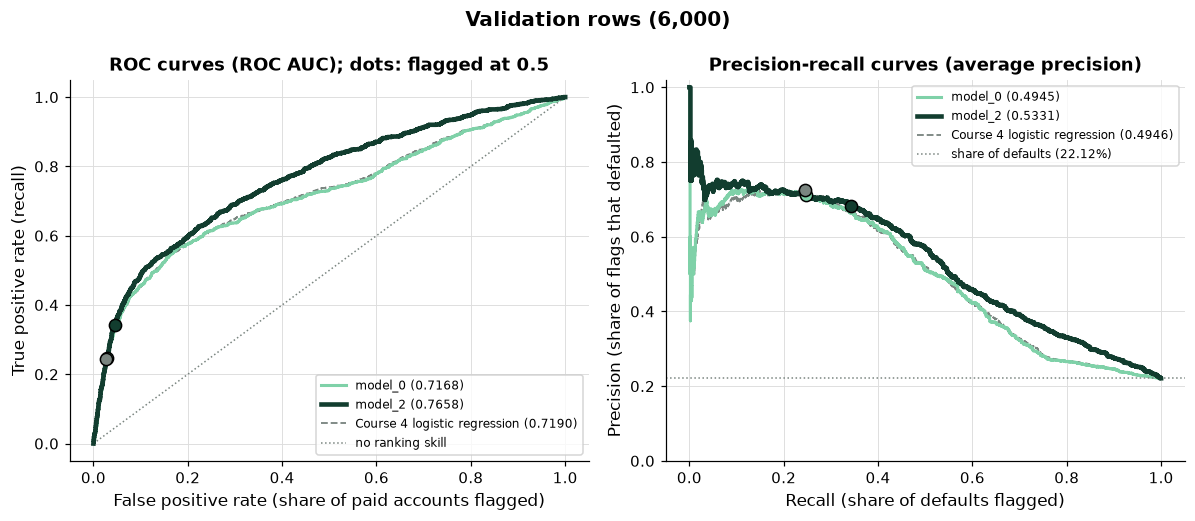

In [44]:
from sklearn.metrics import precision_recall_curve, roc_curve

actual = y_valid.to_numpy() == 1
# colour, line style, width, and drawing order (higher on top)
styles = {chosen: (plotkit.GREEN_DARK, "-", 3, 3), "model_0": (plotkit.GREEN_LIGHT, "-", 2, 2),
          "Course 4 logistic regression": (plotkit.GREY, "--", 1.2, 1)}
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
for name, output in compared.items():
    colour, line, width, order = styles[name]
    false_rate, true_rate, _ = roc_curve(y_valid, output)
    left.plot(false_rate, true_rate, color=colour, linestyle=line, linewidth=width, zorder=order,
              label=f"{name} ({roc_auc_score(y_valid, output):.4f})")
    precision, recall, _ = precision_recall_curve(y_valid, output)
    right.step(recall, precision, where="post", color=colour, linestyle=line, linewidth=width, zorder=order,
               label=f"{name} ({average_precision_score(y_valid, output):.4f})")
    # the point each model reaches when it flags the accounts with output 0.5 or more
    flag = output >= 0.5
    left.plot(flag[~actual].mean(), flag[actual].mean(), "o", color=colour, markersize=8, markeredgecolor="black", zorder=4)
    right.plot(flag[actual].mean(), actual[flag].mean(), "o", color=colour, markersize=8, markeredgecolor="black", zorder=4)
left.plot([0, 1], [0, 1], color=plotkit.GREY, linestyle=":", linewidth=1, label="no ranking skill")
right.axhline(actual.mean(), color=plotkit.GREY, linestyle=":", linewidth=1, label=f"share of defaults ({actual.mean():.2%})")
left.set_title("ROC curves (ROC AUC); dots: flagged at 0.5")
left.set_xlabel("False positive rate (share of paid accounts flagged)")
left.set_ylabel("True positive rate (recall)")
right.set_title("Precision-recall curves (average precision)")
right.set_xlabel("Recall (share of defaults flagged)")
right.set_ylabel("Precision (share of flags that defaulted)")
right.set_ylim(0, 1.02)
left.legend(loc="lower right", fontsize=8)
right.legend(loc="upper right", fontsize=8)
fig.suptitle("Validation rows (6,000)", fontweight="bold")
fig.tight_layout()
plt.show()

* The thick dark line is the chosen network; its ROC AUC is 0.0490 above Model 0's. Model 0's light line and Course 4's dashed grey line nearly coincide, as their ROC AUCs (0.7168 and 0.7190) say: one straight line in the inputs, fitted two ways.
* At 0.5 every dot sits far to the left: the chosen network flags 669 of the 6,000 accounts, Model 0 460.

Q. Draw both networks' confusion matrices at 0.5 on each set of rows they may open: the fit rows, the stopping rows, and the validation rows.

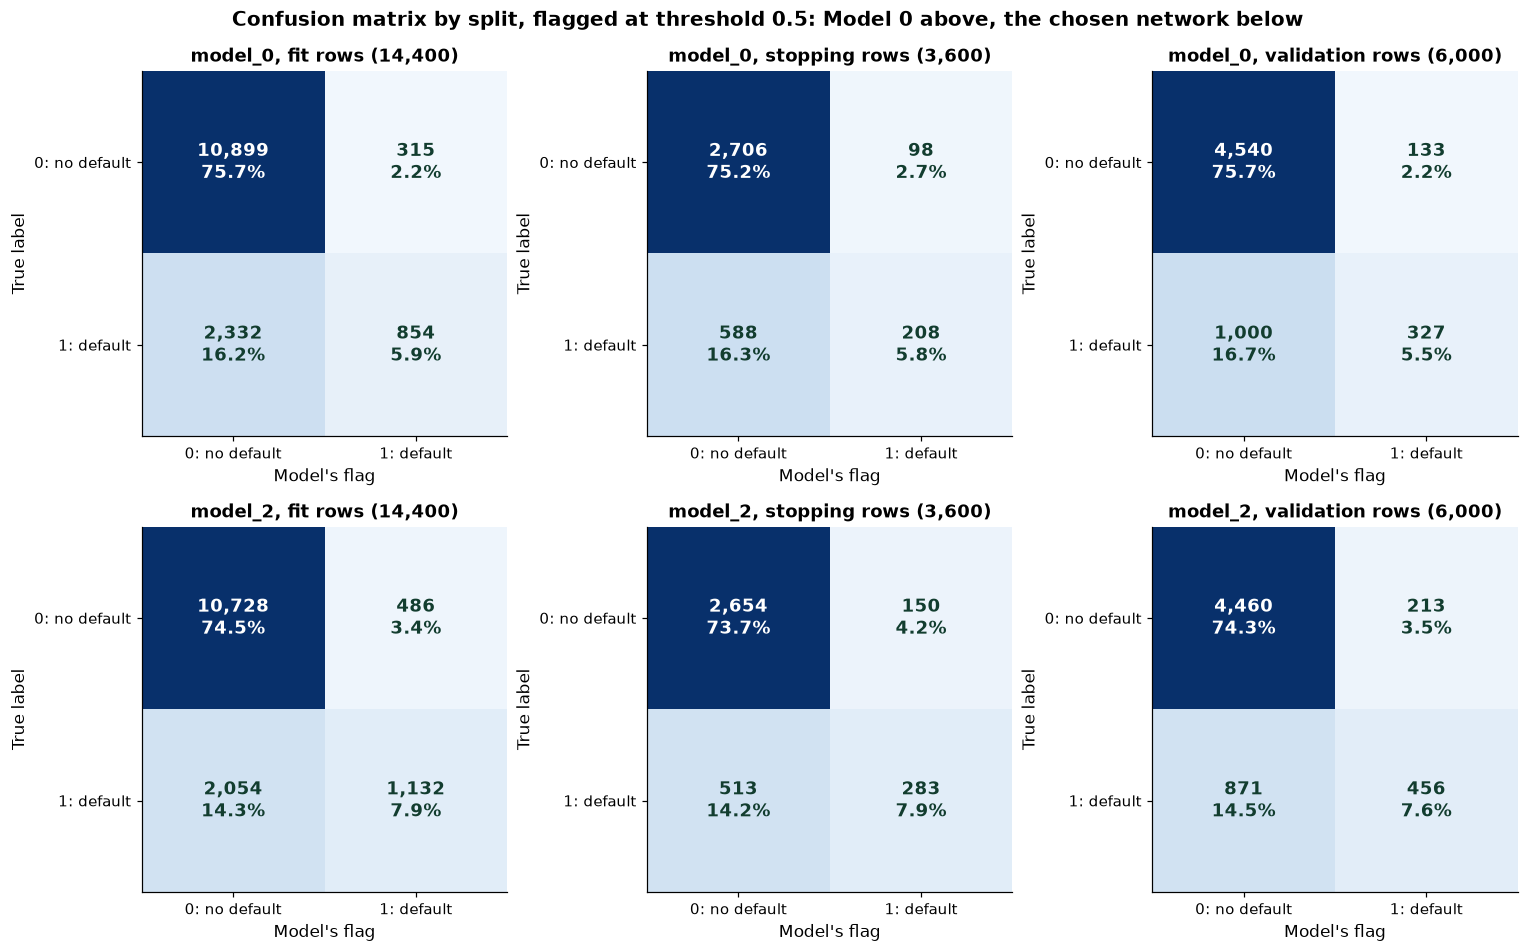

<styled table: Flags at threshold 0.5, by model and split>

In [45]:
# the names of class 0 and class 1, used on every heatmap in the course
labels = ("0: no default", "1: default")
# a Keras model has no predict_proba, so each panel is drawn from its outputs flagged at 0.5
splits = {"fit rows (14,400)": (A_fit, y_fit), "stopping rows (3,600)": (A_stop, y_stop),
          "validation rows (6,000)": (A_valid, y_valid)}
fig, axes = plt.subplots(2, 3, figsize=(14, 8.8))
flag_rows = {}
for row_axes, name in zip(axes, ["model_0", chosen]):
    for ax, (rows_name, (rows, outcome)) in zip(row_axes, splits.items()):
        flag = (models[name].predict(rows, verbose=0)[:, 0] >= 0.5).astype(int)
        plotkit.confusion_heatmap(outcome, flag, f"{name}, {rows_name}", labels, ax=ax)
        flag_rows[(name, rows_name)] = mlkit.classification_metrics(outcome, flag)
fig.suptitle("Confusion matrix by split, flagged at threshold 0.5: Model 0 above, the chosen network below",
             fontweight="bold")
fig.tight_layout()
plt.show()

# the four flag measures for class 1, one row per model and split; nothing is marked: the rows mix models and splits
flag_table = pd.DataFrame(flag_rows).T
flag_table.index.names = ["model", "rows"]
plotkit.styled(flag_table, [], "Flags at threshold 0.5, by model and split", fmt="{:.4f}")

* What happened down the side ("True label"), the network's flag across the top; each cell holds its count and its share of that split's rows. Each row of panels looks alike across the splits: Model 0's recall is 26.8 percent, 26.1 percent, and 24.6 percent on the fit, stopping, and validation rows; the chosen network's 35.5 percent, 35.6 percent, and 34.4 percent. After 20 epochs, neither flags the rows it was fitted on very differently from rows it never saw.
* At 0.5 the chosen network flags more accounts and finds more of the defaults, at a little lower precision: on the validation rows 68.2 percent of its flags defaulted, against 71.1 percent for Model 0. Day 5 chooses a threshold.

> **STORY: an old name for one unit.** In 1958 F. Rosenblatt published a paper titled "The perceptron: A probabilistic model for information storage and organization in the brain." in *Psychological Review* (volume 65, issue 6, pages 386 to 408). "Perceptron" is the name the field still gives a single unit like day 2's neuron, and a "multilayer perceptron" is a network like today's Model 5: units in layers, each layer feeding the next. Today you put layers between the inputs and the output.
>
> Source (read 2026-10-06): the Crossref record of the paper, https://api.crossref.org/works/10.1037/h0042519, DOI https://doi.org/10.1037/h0042519. Only the title, author, journal, volume, issue, pages, and year are taken from it; the paper itself was not read for this course.

## 3.9 What a Hidden Layer Draws

A network with no hidden layer separates its inputs by one straight line. Hidden layers let the line bend. The card file's columns would show it only faintly, so this section uses an invented picture: 300 accounts with two invented readings each, and an outcome of 1 when the two readings have the same sign, with 8 percent of the outcomes flipped at random. The pattern is made up to show what hidden layers can do, and it says nothing about any real file or market. Four networks are fitted to the same 300 accounts and scored on 300 fresh ones drawn the same way. Every network here uses tanh and Adam at 0.02, 300 epochs, batches of 60.

Q. Fit a network with no hidden layer, one with 2 units, one with 8 units, and one with two layers of 8, and draw what each separates.

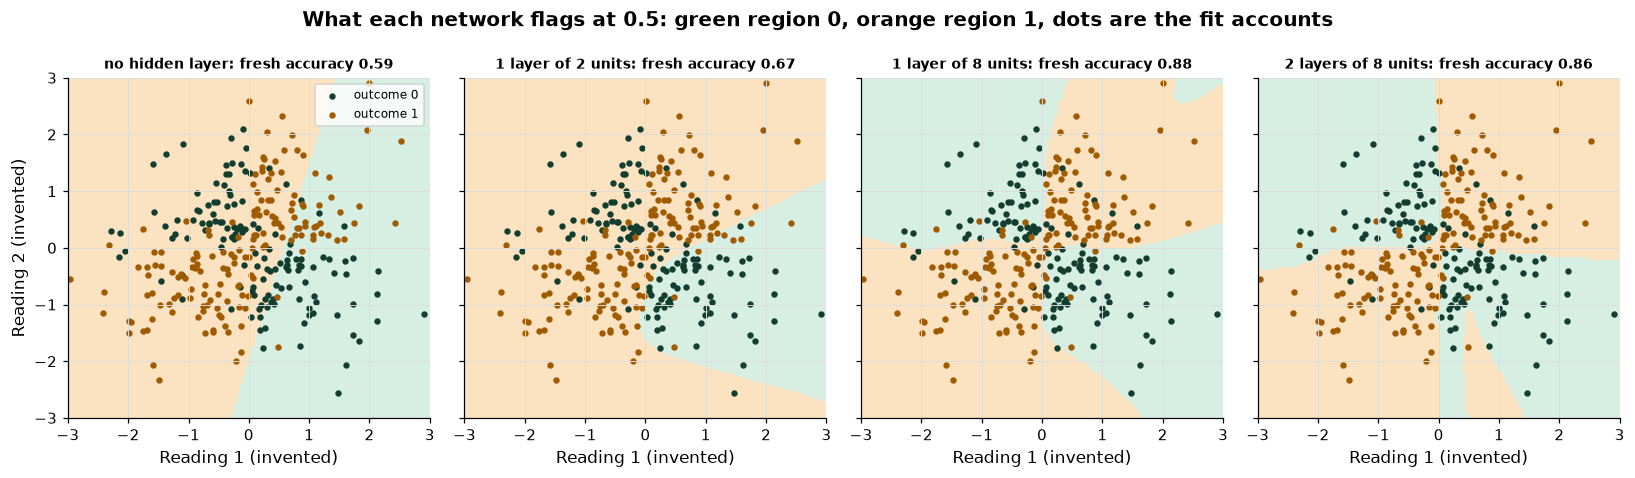

,parameters,"accuracy, fit rows","accuracy, fresh rows"
network,,,
no hidden layer,3,0.600,0.590
1 layer of 2 units,9,0.700,0.670
1 layer of 8 units,33,0.887,0.883
2 layers of 8 units,105,0.927,0.863


In [46]:
# two invented readings per account; the outcome is 1 when they share a sign, with 8 percent flipped
rng = np.random.default_rng(SEED)


def invented_rows(n_rows):
    readings = rng.normal(size=(n_rows, 2))
    outcome_ = ((readings[:, 0] * readings[:, 1]) > 0).astype(float)
    flipped = rng.random(n_rows) < 0.08
    return readings.astype("float32"), np.where(flipped, 1 - outcome_, outcome_).astype("float32")


rows_fit, outcome_fit = invented_rows(300)
rows_new, outcome_new = invented_rows(300)

# a grid of readings to colour: what the network flags at 0.5 everywhere on the picture
grid_x, grid_y = np.meshgrid(np.linspace(-3, 3, 120), np.linspace(-3, 3, 120))
grid = np.c_[grid_x.ravel(), grid_y.ravel()].astype("float32")

specs = {"no hidden layer": (), "1 layer of 2 units": (2,), "1 layer of 8 units": (8,), "2 layers of 8 units": (8, 8)}
fig, axes = plt.subplots(1, 4, figsize=(15, 4.4), sharey=True)
results = {}
for ax, (name, units) in zip(axes, specs.items()):
    keras.utils.set_random_seed(SEED)
    boundary_model = keras.Sequential([keras.Input(shape=(2,))]
                                      + [keras.layers.Dense(u, activation="tanh") for u in units]
                                      + [keras.layers.Dense(1, activation="sigmoid")], name="boundary_trial")
    boundary_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.02), loss="binary_crossentropy")
    boundary_model.fit(rows_fit, outcome_fit, epochs=300, batch_size=60, verbose=0)
    flag = lambda rows: boundary_model.predict(rows, verbose=0)[:, 0] >= 0.5
    results[name] = {"parameters": boundary_model.count_params(), "accuracy, fit rows": (flag(rows_fit) == (outcome_fit == 1)).mean(),
                     "accuracy, fresh rows": (flag(rows_new) == (outcome_new == 1)).mean()}
    # the shaded regions are where the network flags 1 (orange) and 0 (green)
    ax.contourf(grid_x, grid_y, flag(grid).reshape(grid_x.shape), levels=[-0.5, 0.5, 1.5], colors=["#d6efe2", "#fbe3c2"])
    ax.scatter(rows_fit[outcome_fit == 0, 0], rows_fit[outcome_fit == 0, 1], s=10, color=plotkit.GREEN_DARK, label="outcome 0")
    ax.scatter(rows_fit[outcome_fit == 1, 0], rows_fit[outcome_fit == 1, 1], s=10, color="#a05a00", label="outcome 1")
    ax.set_title(f"{name}: fresh accuracy {results[name]['accuracy, fresh rows']:.2f}", fontsize=9)
    ax.set_xlabel("Reading 1 (invented)")
axes[0].set_ylabel("Reading 2 (invented)")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("What each network flags at 0.5: green region 0, orange region 1, dots are the fit accounts", fontweight="bold")
fig.tight_layout()
plt.show()
table = pd.DataFrame(results).T
table["parameters"] = table["parameters"].astype(int)
table.index.name = "network"
plotkit.styled(table, ["accuracy, fit rows", "accuracy, fresh rows"], "Four networks on the invented pattern: 300 fit accounts, 300 fresh ones", fmt="{:.3f}")

* **How to read it:** each panel is the same accounts and the same fitting; only the layers change. With no hidden layer the boundary is one straight line, and the accuracy on fresh accounts is 0.59, barely better than a coin flip, because no straight line separates a pattern built from two crossing ones. Two hidden units give two bends and only 0.67: the pattern needs more than two views. Eight units reach 0.88, with the four quadrants roughly in place.
* A second layer of 8 fits the fit accounts better (0.93 against 0.89) and the fresh ones no better (0.86 against 0.88): its boundary has more corners that follow individual dots. More layers give a network more shapes it can draw, and whether the shapes help depends on the data. That is why section 3.5 chose on stopping rows, and why day 9 is about a network that draws too much.
* The pattern is a made-up picture. On the card file section 3.7 found that width helped a little and depth did not, which is what its own numbers showed.

## 3.10 A Softmax Network on Five Ordered Rating Buckets

**How it works.** Day 2's network ends in one sigmoid unit and answers one question, default or not. A bond's rating bucket is one answer out of five, so the output layer has five units, one per bucket, and each gives a score. **Softmax** (section 3.1) turns the five scores into five probabilities that add to 1, and the model's bucket is the one with the largest probability. The loss is section 3.1's: minus the log of the probability given to the true bucket, which Keras names `sparse_categorical_crossentropy` when the true bucket is stored as one whole number, 0 to 4, in place of a one-hot row of five. You control the hidden layer, as before, and the number of buckets sets the number of output units. What comes out is five probabilities for every bond. A **multinomial logistic regression** is the same output with no hidden layer, softmax over five straight-line scores, and scikit-learn's `LogisticRegression` fits it for any number of groups. LightGBM and XGBoost do the same with `objective="multiclass"` and `objective="multi:softprob"`.

Today's target is a bond's **rating bucket**, in five ordered groups numbered 0 to 4 from the highest quality down: AAA and AA, A, BBB, BB, and B and CCC. The groups are ordered, and that changes how a model should be scored, which is the second half of the section. The 821 bonds are synthetic: their issuers are invented, and their spreads come from the course's generator, `tools/make_holdings.py` (read in this course, never run). The output is the model's rating bucket for a bond with these characteristics. It is not a rating, an internal rating, or a view on any issuer. The generator set each bond's spread from its rating, so a model that reads the spread is recovering how the generator built the file, and it says nothing about a market.

**The inputs are OAS, spread duration, and sector. Coupon is left out.** A coupon reflects the rate regime when a bond was issued as much as its credit quality, so it would mislead. The picture below shows it.

Q. Load Course 4's training bonds, make the five buckets, and draw OAS and coupon by bucket.

821 bonds in the file; 615 training bonds returned; 206 closed
        bonds  OAS median (bp)  coupon 25th (%)  coupon median (%)  coupon 75th (%)
AAA/AA     34             38.0             3.78               4.75             5.59
A         194             73.0             4.16               4.88             5.62
BBB       176            125.0             4.62               5.38             6.25
BB        126            212.0             5.75               6.62             7.47
B/CCC      85            405.0             7.12               8.00            10.00


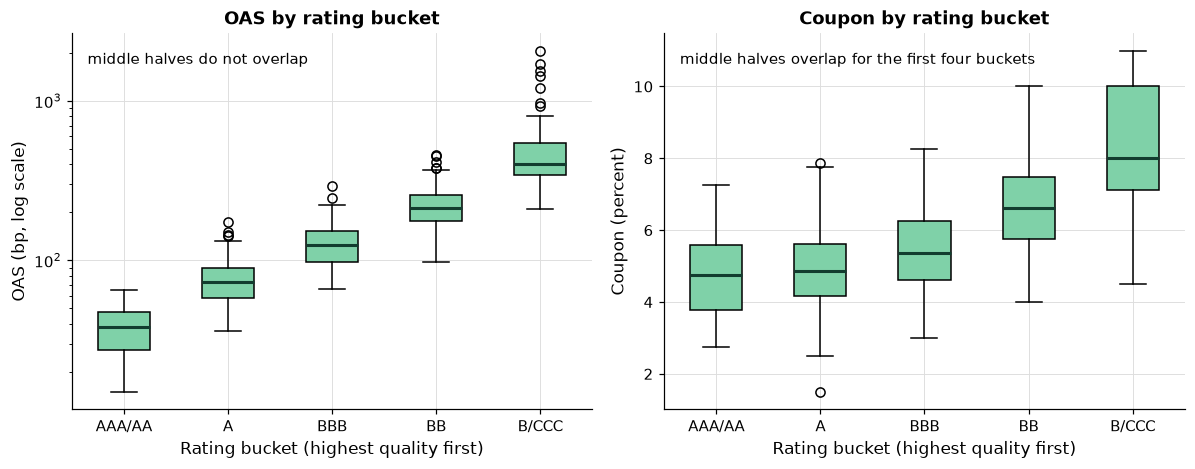

In [47]:
# the synthetic benchmark: Course 4's 615 training bonds (its test bonds are never returned)
bench = pd.read_csv("benchmark.csv")
ratings = pd.read_csv("ratings.csv")
bonds = ensemblekit.course4_bench_rows(bench, ratings)

# five ordered buckets from the file's seven rating groups: 0 is AAA and AA, 4 is B and CCC
bucket_names = ["AAA/AA", "A", "BBB", "BB", "B/CCC"]
bucket_of_group = {"AAA": 0, "AA": 0, "A": 1, "BBB": 2, "BB": 3, "B": 4, "CCC": 4}
bonds["bucket"] = bonds["rating"].map(ratings.set_index("rating")["bucket"].map(bucket_of_group))

by_bucket = bonds.groupby("bucket")
profile = pd.DataFrame({"bonds": by_bucket.size(), "OAS median (bp)": by_bucket["oas"].median(),
                        "coupon 25th (%)": by_bucket["coupon"].quantile(0.25),
                        "coupon median (%)": by_bucket["coupon"].median(),
                        "coupon 75th (%)": by_bucket["coupon"].quantile(0.75)})
profile.index = bucket_names
print(f"{len(bench)} bonds in the file; {len(bonds)} training bonds returned; {len(bench) - len(bonds)} closed")
print(profile.round(2).to_string())

# the same bonds twice: OAS (log scale) and coupon, one box per bucket
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, column, title, ylabel in [(left, "oas", "OAS by rating bucket", "OAS (bp, log scale)"),
                                  (right, "coupon", "Coupon by rating bucket", "Coupon (percent)")]:
    ax.boxplot([bonds.loc[bonds["bucket"] == k, column] for k in range(5)], tick_labels=bucket_names, patch_artist=True,
               boxprops={"facecolor": plotkit.GREEN_LIGHT}, medianprops={"color": plotkit.GREEN_DARK, "linewidth": 2})
    ax.set_title(title)
    ax.set_xlabel("Rating bucket (highest quality first)")
    ax.set_ylabel(ylabel)
left.set_yscale("log")
left.text(0.03, 0.95, "middle halves do not overlap", transform=left.transAxes, va="top", fontsize=10)
right.text(0.03, 0.95, "middle halves overlap for the first four buckets", transform=right.transAxes, va="top", fontsize=10)
plt.tight_layout()
plt.show()

* The 821 bonds are synthetic: their issuers are invented, and their spreads come from the course's generator, `tools/make_holdings.py` (read in this course, never run). 615 training bonds; the 206 test bonds stay closed (day 1's test-row rule). The buckets hold AAA/AA (34), A (194), BBB (176), BB (126), B/CCC (85) bonds.
* **OAS separates the buckets.** The middle half of the bonds in each bucket runs from 27 to 48 bp for AAA/AA, through 98 to 152 bp for BBB, to 345 to 547 bp for B/CCC, and no two buckets' middle halves overlap.
* **Coupon does not.** The middle half of coupons is 3.78 to 5.59 percent for AAA/AA, 4.16 to 5.62 for A, 4.62 to 6.25 for BBB, and 5.75 to 7.47 for BB: the boxes sit on top of each other. A model fed the coupon would learn the issue date's rates as much as the bond's quality.

Q. Hold back a quarter of the 615 bonds, encode the inputs, and fit the softmax network on the rest.

In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# the inputs: log OAS (as in Courses 4 and 5), spread duration, and sector; no coupon
inputs = pd.DataFrame({"log_oas": np.log(bonds["oas"]), "spread_duration": bonds["spread_duration"],
                       "sector": bonds["sector"]})

# Course 4 day 1's split (a random quarter, seed 42), here stratified by bucket so every bucket is in both sets
X_bonds_fit, X_bonds_valid, b_fit, b_valid = train_test_split(
    inputs, bonds["bucket"], test_size=0.25, random_state=SEED, stratify=bonds["bucket"])

# sector as dummy columns, the two numbers in standard units; fitted on the fit bonds only, then applied to both sets
encoder = ColumnTransformer([("sector", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), ["sector"]),
                             ("numbers", StandardScaler(), ["log_oas", "spread_duration"])])
encoder_bonds, A_bonds_fit, A_bonds_valid = netkit.fit_arrays(encoder, X_bonds_fit, X_bonds_valid)
print(f"fit bonds {A_bonds_fit.shape}, held-back bonds {A_bonds_valid.shape}, {bonds['sector'].nunique()} sectors")

# seed before building any Keras model, so its numbers never depend on what ran before
keras.utils.set_random_seed(SEED)
# five softmax units: one probability per bucket
bucket_net = keras.Sequential([keras.Input(shape=(A_bonds_fit.shape[1],)),
                               keras.layers.Dense(16, activation="relu", name="hidden"),
                               keras.layers.Dense(5, activation="softmax", name="output")], name="bucket_softmax")
# the true bucket is one whole number per bond, so the loss is the sparse version of categorical cross-entropy
bucket_net.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss="sparse_categorical_crossentropy")
bucket_net.fit(A_bonds_fit, b_fit.to_numpy(), epochs=100, batch_size=32, verbose=0)

bucket_proba = bucket_net.predict(A_bonds_valid, verbose=0)
bucket_net_bucket = bucket_proba.argmax(axis=1)
print(f"parameters {bucket_net.count_params()}; netkit.parameter_count equal: "
      f"{netkit.parameter_count([A_bonds_fit.shape[1], 16, 5]) == bucket_net.count_params()}")

# the first five held-back bonds: five probabilities that add to 1, and the bucket with the largest
first_bonds = pd.DataFrame(bucket_proba[:5], columns=bucket_names, index=X_bonds_valid.index[:5])
first_bonds["adds to"] = first_bonds.sum(axis=1)
first_bonds["model's bucket"] = [bucket_names[k] for k in bucket_net_bucket[:5]]
first_bonds["true bucket"] = [bucket_names[k] for k in b_valid.iloc[:5]]
print(first_bonds.round(3).to_string())

fit bonds (461, 12), held-back bonds (154, 12), 10 sectors


parameters 293; netkit.parameter_count equal: True
     AAA/AA      A    BBB     BB  B/CCC  adds to model's bucket true bucket
175   0.000  0.002  0.942  0.056  0.000      1.0            BBB         BBB
339   0.000  0.090  0.910  0.000  0.000      1.0            BBB         BBB
108   0.002  0.983  0.015  0.000  0.000      1.0              A           A
726   0.000  0.000  0.001  0.990  0.009      1.0             BB          BB
459   0.000  0.350  0.460  0.190  0.000      1.0            BBB         BBB


* 461 bonds to fit and 154 held back, each with 12 columns: 10 sector dummies and the two numbers. The network has 293 parameters, 12 x 16 + 16 in the hidden layer and 16 x 5 + 5 in the output, and `parameter_count` agrees with Keras. Nothing was tuned on the 154 held-back bonds: the 16 ReLU units, Adam at 0.01, 100 epochs, and batches of 32 were set once.
* Each row of probabilities adds to 1, and the model's bucket is the largest. The table prints the first five bonds' (the row labels are positions in the benchmark file).

Q. Fit the multinomial logistic regression on the same bonds, and draw both models' 5 x 5 confusion matrices on the held-back bonds, with their accuracy.

accuracy on the 154 held-back bonds: softmax network 0.6948, multinomial logistic regression 0.7143
always naming the largest bucket would be right 0.3182 of the time


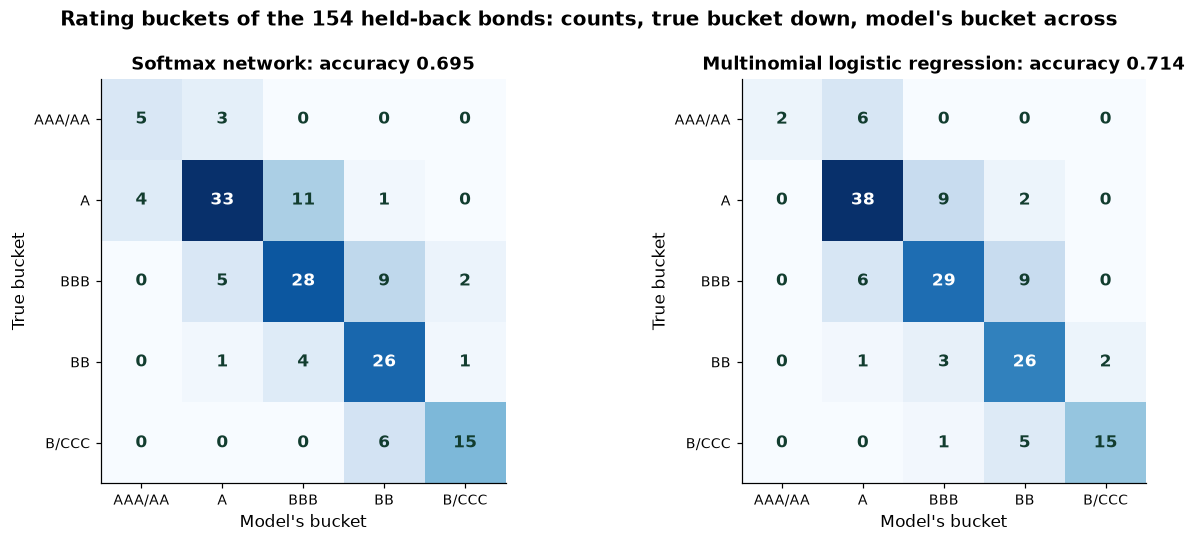

In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.pipeline import Pipeline

# the same encoder in a pipeline, so the encoding is fitted on the fit bonds only; scikit-learn's default is multinomial
bucket_logistic = Pipeline([("encode", encoder), ("model", LogisticRegression(max_iter=2000))]).fit(X_bonds_fit, b_fit)
bucket_logistic_bucket = bucket_logistic.predict(X_bonds_valid)

accuracy_net = accuracy_score(b_valid, bucket_net_bucket)
accuracy_logistic = accuracy_score(b_valid, bucket_logistic_bucket)
largest = b_valid.value_counts().max() / len(b_valid)
print(f"accuracy on the {len(b_valid)} held-back bonds: softmax network {accuracy_net:.4f}, "
      f"multinomial logistic regression {accuracy_logistic:.4f}")
print(f"always naming the largest bucket would be right {largest:.4f} of the time")


def bucket_heatmap(ax, counts, title):
    """A 5 by 5 confusion matrix: the true bucket down the side, the model's bucket across the top, the count in each cell."""
    ax.imshow(counts, cmap="Blues", vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(5):
        for col in range(5):
            ax.text(col, row, f"{counts[row, col]}", ha="center", va="center", fontsize=11, fontweight="bold",
                    color="white" if counts[row, col] > counts.max() / 2 else plotkit.GREEN_DARK)
    ax.set_xticks(range(5), labels=bucket_names, fontsize=9)
    ax.set_yticks(range(5), labels=bucket_names, fontsize=9)
    ax.set_xlabel("Model's bucket")
    ax.set_ylabel("True bucket")
    ax.set_title(title)


counts_net = confusion_matrix(b_valid, bucket_net_bucket, labels=range(5))
counts_logistic = confusion_matrix(b_valid, bucket_logistic_bucket, labels=range(5))
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 5))
bucket_heatmap(left, counts_net, f"Softmax network: accuracy {accuracy_net:.3f}")
bucket_heatmap(right, counts_logistic, f"Multinomial logistic regression: accuracy {accuracy_logistic:.3f}")
fig.suptitle(f"Rating buckets of the {len(b_valid)} held-back bonds: counts, true bucket down, model's bucket across", fontweight="bold")
fig.tight_layout()
plt.show()

**Rows.** Every model in this section is fitted on 461 of Course 4's 615 training bonds and scored on the other 154, held back before any fitting; Course 4's 206 test bonds are never scored in this course.

* Both models put most bonds on or next to the diagonal: accuracy 0.6948 for the network and 0.7143 for the logistic regression, against 0.3182 for always naming the largest bucket. The network's 47 misses are 43 one bucket away and 4 two buckets away, A softmax network and a straight-line model do about the same here, which fits a generator that sets spreads from rating, maturity, an issuer effect, and noise.
* Accuracy counts a miss by one bucket and a miss by four the same. The buckets are ordered, so the next measure should not.

### Quadratic weighted kappa

**How it works.** Accuracy marks a bond right or wrong, so calling a BBB bond BB scores the same as calling it B or CCC, though the second is further from the truth. **Quadratic weighted kappa** (QWK) is built from three 5 x 5 tables. The *observed* table is the confusion matrix. The *expected* table is what it would hold if the model's buckets had nothing to do with the true ones: each cell is its row total times its column total, divided by the number of bonds. The *weight* table is 0 on the diagonal and grows with the square of the distance between two buckets, scaled so the farthest pair costs 1; calling a BBB bond BB (one bucket away) costs 1/16, and calling it B or CCC (two away) costs 4/16. QWK is 1 minus the weighted observed disagreement divided by the weighted expected disagreement: 1 is perfect agreement, 0 is no better than the chance table, and below 0 is worse. You control the weights, `"quadratic"` here or `"linear"` (exercise 5). What comes out is one number, which scikit-learn's `cohen_kappa_score(..., weights="quadratic")` also computes.

Q. Draw the weight table.

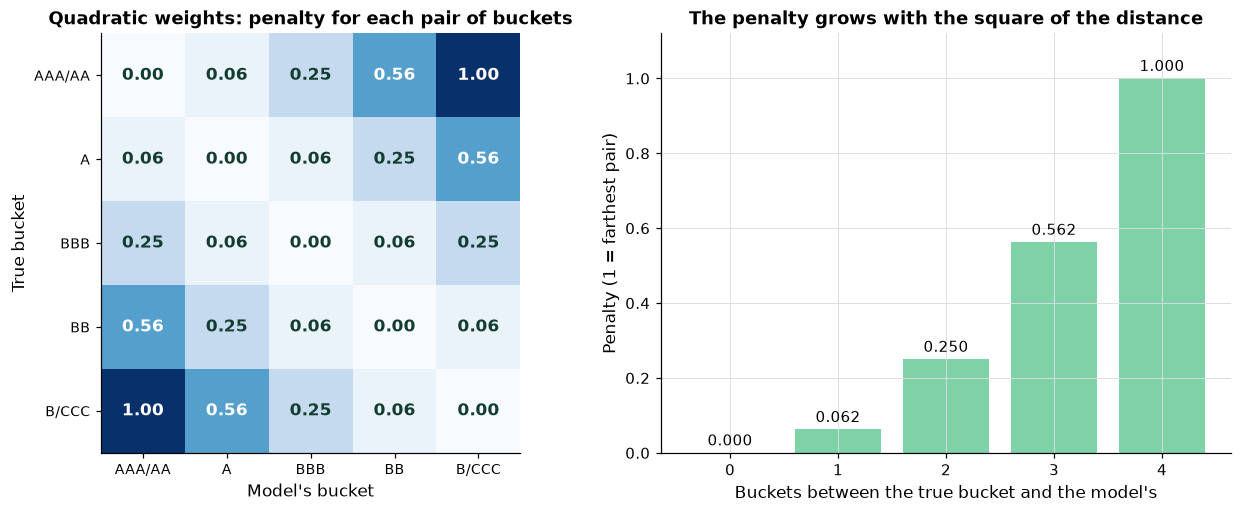

In [50]:
# the penalty for calling true bucket i bucket j: the squared distance, scaled so the farthest pair (4 apart) costs 1
distance = np.subtract.outer(np.arange(5), np.arange(5))
weight_table = distance ** 2 / (5 - 1) ** 2

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
left.imshow(weight_table, cmap="Blues", vmin=0, vmax=1)
left.grid(False)
for row in range(5):
    for col in range(5):
        left.text(col, row, f"{weight_table[row, col]:.2f}", ha="center", va="center", fontsize=11, fontweight="bold",
                  color="white" if weight_table[row, col] > 0.5 else plotkit.GREEN_DARK)
left.set_xticks(range(5), labels=bucket_names, fontsize=9)
left.set_yticks(range(5), labels=bucket_names, fontsize=9)
left.set_xlabel("Model's bucket")
left.set_ylabel("True bucket")
left.set_title("Quadratic weights: penalty for each pair of buckets")
# the first row is the penalty by distance: 0 to 4 buckets away
right.bar(range(5), weight_table[0], color=plotkit.GREEN_LIGHT)
for k in range(5):
    right.text(k, weight_table[0, k] + 0.02, f"{weight_table[0, k]:.3f}", ha="center", fontsize=10)
right.set_ylim(0, 1.12)
right.set_xlabel("Buckets between the true bucket and the model's")
right.set_ylabel("Penalty (1 = farthest pair)")
right.set_title("The penalty grows with the square of the distance")
plt.tight_layout()
plt.show()

* Zero on the diagonal, 1/16 = 0.0625 for a miss by one bucket, 0.25 for two, 0.5625 for three, and 1 for four. A miss by two costs four times a miss by one, and a miss by four costs sixteen times as much.

Q. Work QWK out by hand from the network's confusion matrix, and check it against scikit-learn.

In [51]:
from sklearn.metrics import cohen_kappa_score

# observed: the confusion matrix; expected: row total times column total over the number of bonds
observed = confusion_matrix(b_valid, bucket_net_bucket, labels=range(5))
expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / observed.sum()
print("expected counts if the model's buckets had nothing to do with the true ones:")
print(pd.DataFrame(expected, index=bucket_names, columns=bucket_names).round(1).to_string())

# the weighted disagreement of each table, then QWK = 1 - observed / expected
penalty_observed = (weight_table * observed).sum()
penalty_expected = (weight_table * expected).sum()
qwk_by_hand = 1 - penalty_observed / penalty_expected
qwk_sklearn = cohen_kappa_score(b_valid, bucket_net_bucket, weights="quadratic")
print(f"weighted disagreement: observed {penalty_observed:.4f}, expected {penalty_expected:.4f}")
print(f"QWK by hand {qwk_by_hand:.4f}; cohen_kappa_score(weights='quadratic') {qwk_sklearn:.4f}; "
      f"equal within 1e-12: {abs(qwk_by_hand - qwk_sklearn) < 1e-12}")

expected counts if the model's buckets had nothing to do with the true ones:
        AAA/AA     A   BBB    BB  B/CCC
AAA/AA     0.5   2.2   2.2   2.2    0.9
A          2.9  13.4  13.7  13.4    5.7
BBB        2.6  12.0  12.3  12.0    5.1
BB         1.9   8.7   8.9   8.7    3.7
B/CCC      1.2   5.7   5.9   5.7    2.5
weighted disagreement: observed 3.6875, expected 24.1810
QWK by hand 0.8475; cohen_kappa_score(weights='quadratic') 0.8475; equal within 1e-12: True


* The model's misses add up to 3.6875 of weighted disagreement; a model unrelated to the truth, with the same row and column totals, would add up to 24.1810. 3.6875 / 24.1810 is 0.1525 of the chance level, so QWK is 1 - 0.1525 = 0.8475. By hand and scikit-learn agree.
* Expected counts are not whole numbers: they are averages over all the ways the model's buckets could have been unrelated to the true ones.

Q. Score both models with accuracy and with QWK.

In [52]:
def quadratic_kappa(true, named):
    """QWK by hand: 1 minus the weighted observed disagreement over the weighted expected disagreement."""
    counts = confusion_matrix(true, named, labels=range(5))
    chance = np.outer(counts.sum(axis=1), counts.sum(axis=0)) / counts.sum()
    return 1 - (weight_table * counts).sum() / (weight_table * chance).sum()


bucket_scores = pd.DataFrame({"accuracy": [accuracy_net, accuracy_logistic],
                       "quadratic weighted kappa": [quadratic_kappa(b_valid, bucket_net_bucket),
                                                    quadratic_kappa(b_valid, bucket_logistic_bucket)]},
                      index=["softmax network", "multinomial logistic regression"])
plotkit.styled(bucket_scores, ["accuracy", "quadratic weighted kappa"],
               f"Rating buckets of the {len(b_valid)} held-back bonds: accuracy and quadratic weighted kappa", fmt="{:.4f}")

,accuracy,quadratic weighted kappa
softmax network,0.6948,0.8475
multinomial logistic regression,0.7143,0.8460


* The network's QWK is 0.8475 and the logistic regression's 0.8460: the two models agree with the true buckets about equally well, and their misses are almost all one bucket away, which is why QWK is high while accuracy is 0.6948. On 154 bonds, differences this small are within what a different split could move.

Q. Can two models share an accuracy and differ widely in QWK? Keep the network's 47 misses and move them: once every miss one bucket away, once every miss as far as the scale allows.

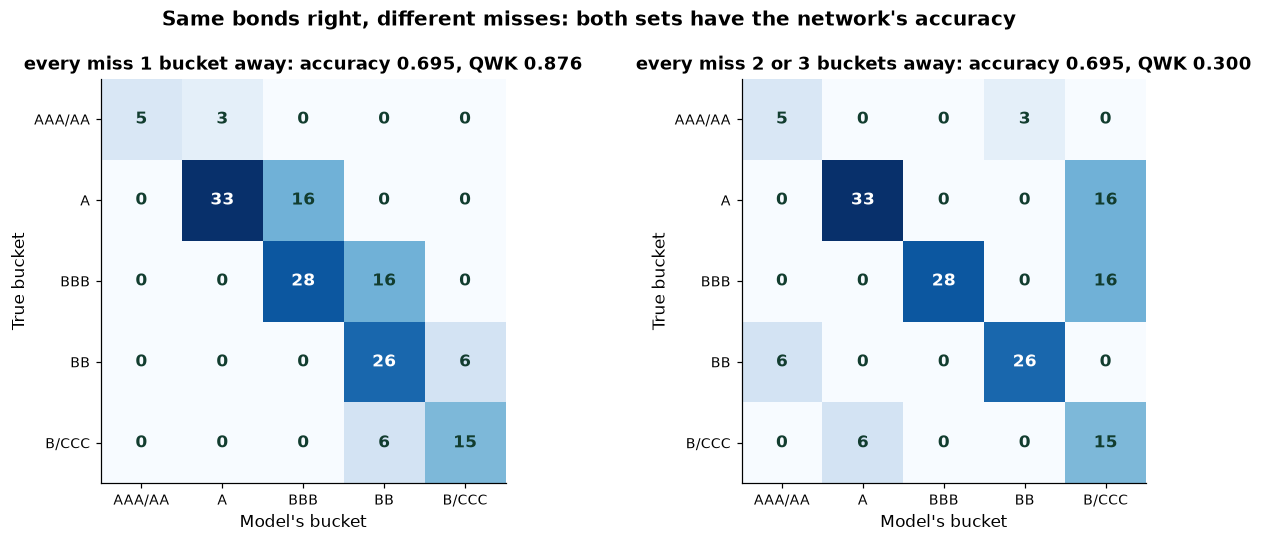

,bonds right,accuracy,largest miss (buckets),quadratic weighted kappa
set of buckets,,,,
the network,107,0.6948,2,0.8475
every miss 1 bucket away,107,0.6948,1,0.8763
every miss 2 or 3 buckets away,107,0.6948,3,0.2996


In [53]:
# same bonds, same bonds right; only where the wrong ones land changes (illustrations built from the true buckets)
true_bucket = b_valid.to_numpy()
wrong = bucket_net_bucket != true_bucket
# every miss exactly one bucket away (up, or down for the last bucket)
near = np.where(wrong, np.where(true_bucket < 4, true_bucket + 1, true_bucket - 1), true_bucket)
# every miss as far as the scale allows: AAA/AA to BB, A to B/CCC, BBB to B/CCC, BB to AAA/AA, B/CCC to A
far = np.where(wrong, np.array([3, 4, 4, 0, 1])[true_bucket], true_bucket)

sets = {"the network": bucket_net_bucket, "every miss 1 bucket away": near, "every miss 2 or 3 buckets away": far}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, named) in zip(axes, [("every miss 1 bucket away", near), ("every miss 2 or 3 buckets away", far)]):
    bucket_heatmap(ax, confusion_matrix(true_bucket, named, labels=range(5)),
                   f"{name}: accuracy {accuracy_score(true_bucket, named):.3f}, QWK {quadratic_kappa(true_bucket, named):.3f}")
fig.suptitle("Same bonds right, different misses: both sets have the network's accuracy", fontweight="bold")
fig.tight_layout()
plt.show()

compare = pd.DataFrame({
    "bonds right": [int((named == true_bucket).sum()) for named in sets.values()],
    "accuracy": [accuracy_score(true_bucket, named) for named in sets.values()],
    "largest miss (buckets)": [int(np.abs(named - true_bucket).max()) for named in sets.values()],
    "quadratic weighted kappa": [quadratic_kappa(true_bucket, named) for named in sets.values()]}, index=list(sets))
compare.index.name = "set of buckets"
plotkit.styled(compare, ["quadratic weighted kappa"], "Same accuracy, different quadratic weighted kappa", fmt="{:.4f}")

* All three sets get 107 of 154 bonds right, accuracy 0.6948, and accuracy cannot tell them apart. QWK can: 0.8763 when every miss is one bucket away, the network's 0.8475 in between, and 0.2996 when every miss is two or three away. The sets other than the network's are illustrations built from the true buckets, not models.
* **Use QWK when the groups are ordered and the size of a miss matters.** It describes how well these buckets agree on this synthetic file, where the generator set spreads by rating; it says nothing about any real bond, rating, or market.

## Excel Side by Side

Excel has no Keras and no network training: nothing in it fits a hidden layer's weights. What it can do is everything a fitted or hand-weighted network does to a row, because each unit is a `SUMPRODUCT` and an activation. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-06). The activations were tested on the seven values of section 3.1; the two-unit layer on all 14,400 fit rows, with scaled `PAY_0` in column A and scaled `LIMIT_BAL` in column B of a sheet named `layer`, and section 3.2's weights pasted as their float32 values in L2:N5 (one row per hidden unit: the `PAY_0` weight, the `LIMIT_BAL` weight, the intercept; row 5 the output neuron's).

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| ReLU | `np.maximum(0, z)`, `keras.activations.relu` | `=MAX(0,A2)` | 0.5, 2, 4 at z = 0.5, 2, 4 |
| tanh | `np.tanh(z)`, `keras.activations.tanh` | `=TANH(A2)` | 0.9993 at z = 4 |
| sigmoid | `1 / (1 + np.exp(-z))` | `=1/(1+EXP(-A2))` | 0.9820 at z = 4 |
| ReLU hidden unit 1 | `np.maximum(0.0, rows @ k + b)[:, 0]` | `=MAX(0,SUMPRODUCT($A2:$B2,$L$2:$M$2)+$N$2)` in C2, filled down | equal to numpy within 1e-12 |
| ReLU hidden unit 2 | the same, column 1 | `=MAX(0,SUMPRODUCT($A2:$B2,$L$3:$M$3)+$N$3)` in D2 | equal to numpy within 1e-12 |
| The output neuron | `1 / (1 + np.exp(-(relu_hidden @ v + c)))` | `=1/(1+EXP(-(SUMPRODUCT(C2:D2,$L$5:$M$5)+$N$5)))` in E2 | equal to `forward_pass` within 1e-12, to `model.predict` within 1e-6 |
| tanh hidden units and output | `np.tanh(rows @ k + b)`, then the same output | `=TANH(SUMPRODUCT($A2:$B2,$L$2:$M$2)+$N$2)` in F2, `=TANH(SUMPRODUCT($A2:$B2,$L$3:$M$3)+$N$3)` in G2, `=1/(1+EXP(-(SUMPRODUCT(F2:G2,$L$5:$M$5)+$N$5)))` in H2 | equal to `forward_pass` within 1e-12, to `model.predict` within 1e-6 |
| Parameters of Model 4 | `netkit.parameter_count([19, 32, 1])` | `=19*32+32+32*1+1` | 673 |
| Parameters of Model 5 | `netkit.parameter_count([19, 32, 16, 1])` | `=19*32+32+32*16+16+16*1+1` | 1,185 |

**A unit is a SUMPRODUCT.** `SUMPRODUCT($A2:$B2,$L$2:$M$2)` multiplies the row's two inputs by unit 1's two weights and adds them up, the `rows @ k` of section 3.2 for one unit; `+$N$2` adds its intercept. Wrapped in `MAX(0, ...)` it is a ReLU unit, in `TANH(...)` a tanh unit. The dollar signs keep the weights fixed while the row moves as you fill down.

**The output neuron is the same idea one layer on.** Its inputs are the two hidden units in C2:D2, its weights are row 5, and `1/(1+EXP(-(...)))` is the sigmoid. Three columns per network, filled down 14,400 rows, give the network's output for every fit row.

**The charts.** The ladder's bars and lines (sections 3.5 and 3.7) are what Excel draws as a clustered column chart and a line chart from the same table.

**Counting parameters is arithmetic.** Each layer adds inputs times units plus units; the formula writes the layers out one after another. Excel and Keras agree on every count the notebook shows (20, 673, 1,185, and the exercises' 1,345 and 1,313); the foundation tested 337 for 16 units.

Q. Do Excel's first five rows equal Python's?

In [54]:
# Excel's first five rows of the layer sheet (the ReLU network's units and output, and the tanh output), from the
# course's Excel check, beside section 3.2's hand calculation for the same rows
excel = pd.DataFrame({"relu unit 1": [2.2872663741217565, 0.0, 2.077748880892944, 0.0, 0.5819523257792909],
                      "relu unit 2": [1.7767982114509664, 0.7698759008465146, 1.1482457733919134, 0.0, 0.0],
                      "relu output": [0.9627570391503385, 0.27207915181387454, 0.9194738723622822, 0.16798161153384708, 0.325837687545345],
                      "tanh output": [0.6513235586313959, 0.10236904891937543, 0.6242037502849488, 0.03666150932279305, 0.23812288088979824]})
python = first[["relu unit 1", "relu unit 2", "relu output", "tanh output"]]
print(excel.round(6).to_string())
print(f"Excel equal to Python within 1e-12 in all {excel.size} cells: {bool((excel - python).abs().max().max() < 1e-12)}")

   relu unit 1  relu unit 2  relu output  tanh output
0     2.287266     1.776798     0.962757     0.651324
1     0.000000     0.769876     0.272079     0.102369
2     2.077749     1.148246     0.919474     0.624204
3     0.000000     0.000000     0.167982     0.036662
4     0.581952     0.000000     0.325838     0.238123
Excel equal to Python within 1e-12 in all 20 cells: True


* All twenty cells agree within 1e-12. On all 14,400 fit rows, the check found Excel's outputs equal to `forward_pass` within 1e-12 and to `model.predict` within 1e-6 for both networks; the larger gap is Keras's float32.

### Quadratic weighted kappa in Excel

Section 3.10's QWK is three 5 x 5 blocks and a `SUMPRODUCT`. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-20), on the 154 held-back bonds: the true bucket in A2:A155 and the network's bucket in B2:B155 of a sheet named `qwk`, with the labels 0 to 4 down the side and across the top of each block (column G and rows 1, 9, 17, and 25).

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| Observed counts, H2:L6 | `confusion_matrix(true, named)` | `=COUNTIFS($A$2:$A$155,$G2,$B$2:$B$155,H$1)` | the confusion matrix, cell for cell |
| Expected counts, H10:L14 | `np.outer(rows, columns) / n` | `=SUM($H2:$L2)*SUM(H$2:H$6)/SUM($H$2:$L$6)` | row total times column total over N |
| Quadratic weights, H18:L22 | `distance ** 2 / (5 - 1) ** 2` | `=($G18-H$17)^2/(5-1)^2` | 0, 0.0625, 0.25, 0.5625, 1 across the first row |
| Quadratic weighted kappa | `1 - (w * o).sum() / (w * e).sum()` | `=1-SUMPRODUCT(H18:L22,H2:L6)/SUMPRODUCT(H18:L22,H10:L14)` | 0.8475 |
| Linear weights, H26:L30 | `np.abs(distance) / (5 - 1)` | `=ABS($G26-H$25)/(5-1)` | 0, 0.25, 0.5, 0.75, 1 across the first row |
| Linear weighted kappa | the same, with the linear weights | `=1-SUMPRODUCT(H26:L30,H2:L6)/SUMPRODUCT(H26:L30,H10:L14)` | 0.7345 |
| Accuracy | `accuracy_score(true, named)` | `=SUMPRODUCT(--(A2:A155=B2:B155))/COUNT(A2:A155)` | 0.6948 |

**The observed block is a count.** `COUNTIFS` counts the bonds whose true bucket equals the row label (`$G2`) and whose model bucket equals the column label (`H$1`). Filled over a 5 x 5 range it is the confusion matrix, and its diagonal over its total is the accuracy.

**The expected block is a product of totals.** `SUM($H2:$L2)` is the row's total, with the dollar signs fixing the columns; `SUM(H$2:H$6)` is the column's total, with the dollar signs fixing the rows; their product over `SUM($H$2:$L$6)`, the number of bonds, is what the cell would hold if the model's bucket and the true bucket were unrelated.

**The weights are a formula of two labels.** `($G18-H$17)^2/(5-1)^2` squares the distance between the row label and the column label and scales it so the farthest pair is 1. Without the square, `ABS($G26-H$25)/(5-1)` gives the linear weights of exercise 5.

**QWK is one cell.** `SUMPRODUCT(H18:L22,H2:L6)` multiplies the weight block by the observed block cell by cell and adds the products; the same with the expected block is the chance level; one minus their ratio is QWK.

Q. Do Excel's three results equal Python's?

In [55]:
# Excel's results from the course's Excel check (section 3.10's 154 held-back bonds), beside Python's
kappa_table = pd.DataFrame({
    "Excel": {"quadratic weighted kappa": 0.8475042798160518, "linear weighted kappa": 0.734518658734451,
              "accuracy": 0.6948051948051948},
    "Python": {"quadratic weighted kappa": qwk_by_hand, "linear weighted kappa": cohen_kappa_score(b_valid, bucket_net_bucket, weights="linear"),
               "accuracy": accuracy_net}})
kappa_table["within 1e-12"] = (kappa_table["Excel"] - kappa_table["Python"]).abs() < 1e-12
print(kappa_table.round(6).to_string())

                             Excel    Python  within 1e-12
quadratic weighted kappa  0.847504  0.847504          True
linear weighted kappa     0.734519  0.734519          True
accuracy                  0.694805  0.694805          True


* All three agree within 1e-12. The observed block Excel counted equals the confusion matrix of section 3.10, cell for cell.

## Save the Day with Git

Every day's work folder starts fresh, so today's repository starts with today's files: the two earlier modules, unchanged, and `netkit.py` and its tests with today's functions. Then the experiment log goes in two commits, so its history has something to show.

Q. Make the work folder a repository.

In [56]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [57]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course6_03_qf3_06ry and nowhere else


Q. Tell Git which files never to track, and commit the code.

In [58]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx
*.keras

Writing .gitignore


In [59]:
!git -C "{work}" add .gitignore mlkit.py ensemblekit.py netkit.py test_netkit.py
!git -C "{work}" commit -q -m "netkit day 3: forward_pass and parameter_count, 15 tests"
!git -C "{work}" show --stat --format=%s HEAD

netkit day 3: forward_pass and parameter_count, 15 tests

 .gitignore     |   4 +
 ensemblekit.py | 624 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 mlkit.py       | 568 +++++++++++++++++++++++++++++++++++++++++++++++++++
 netkit.py      | 199 ++++++++++++++++++
 test_netkit.py | 190 ++++++++++++++++++
 5 files changed, 1585 insertions(+)


Q. Write the first row of the experiment log, Model 0 on the validation rows, and commit it.

In [60]:
def log_rows(outputs: dict) -> pd.DataFrame:
    """One row per model: validation ranking metrics, and flags at 0.5 scored by mlkit.classification_metrics."""
    rows = []
    for name, output in outputs.items():
        metrics = mlkit.classification_metrics(y_valid, (output >= 0.5).astype(int))
        rows.append({"model": name, "rows": "validation", "roc_auc": roc_auc_score(y_valid, output),
                     "average_precision": average_precision_score(y_valid, output), "threshold": 0.5, **metrics})
    return pd.DataFrame(rows)


logged = {"model_0_one_neuron": valid_outputs["model_0"]}
# 4 decimals and LF line endings, so a later diff shows only real changes
log_rows(logged).to_csv("results.csv", index=False, float_format="%.4f", lineterminator="\n")
print((work / "results.csv").read_text(encoding="utf-8"))

model,rows,roc_auc,average_precision,threshold,accuracy,precision,recall,f1
model_0_one_neuron,validation,0.7168,0.4945,0.5000,0.8112,0.7109,0.2464,0.3660



In [61]:
!git -C "{work}" add results.csv
!git -C "{work}" commit -q -m "Experiment log: Model 0, one neuron on 19 scaled columns, validation"

Q. Add the chosen network to the log, and commit again.

In [62]:
logged["model_2_16_tanh"] = valid_outputs[chosen]
log_rows(logged).to_csv("results.csv", index=False, float_format="%.4f", lineterminator="\n")
print((work / "results.csv").read_text(encoding="utf-8"))
print(f"accuracy of flagging no account (all-zero baseline) on the validation rows: {1 - y_valid.mean():.4f}")

model,rows,roc_auc,average_precision,threshold,accuracy,precision,recall,f1
model_0_one_neuron,validation,0.7168,0.4945,0.5000,0.8112,0.7109,0.2464,0.3660
model_2_16_tanh,validation,0.7658,0.5331,0.5000,0.8193,0.6816,0.3436,0.4569

accuracy of flagging no account (all-zero baseline) on the validation rows: 0.7788


* The threshold is 0.5 for both, as on days 1 and 2; from day 5 it comes from out-of-fold outputs on the training rows. At 0.5 the chosen network's recall is 0.3436 against the neuron's 0.2464. Accuracy is printed beside the all-zero baseline (0.7788) and never used to choose.

In [63]:
!git -C "{work}" add results.csv
!git -C "{work}" commit -q -m "Experiment log: add Model 2, chosen on the stopping rows, validation"

Q. Today's Git step: which commits touched `results.csv`?

In [64]:
# the whole history, then only the commits that changed results.csv
!git -C "{work}" log --oneline
!git -C "{work}" log --oneline -- results.csv

8d270c9 Experiment log: add Model 2, chosen on the stopping rows, validation
bc92c5a Experiment log: Model 0, one neuron on 19 scaled columns, validation
911e8e6 netkit day 3: forward_pass and parameter_count, 15 tests


8d270c9 Experiment log: add Model 2, chosen on the stopping rows, validation
bc92c5a Experiment log: Model 0, one neuron on 19 scaled columns, validation


* `git log --oneline` lists all three commits; adding `-- results.csv` keeps only the two that changed the log. With a path after `--`, Git shows the history of that one file: when the experiment log changed, and with which message, without the code commits in between.

## Bring It Home

Add today's two functions to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to the folder and check that day 2's tests pass.

```powershell
Set-Location "$HOME\projects\my_bondmath"
python -m pytest -q test_netkit.py
```

The last line says `10 passed`.

**Step 2.** Paste the code of today's two `%%writefile -a netkit.py` cells (sections 3.3 and 3.4), without their first lines, at the end of `netkit.py`, and the two `%%writefile -a test_netkit.py` cells at the end of `test_netkit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_netkit.py
```

The last line says `15 passed`.

**Step 4.** Read the change, then commit it.

```powershell
git diff --stat
git add netkit.py test_netkit.py
git commit -m "netkit day 3: forward_pass and parameter_count, 15 tests"
git log --oneline -3
```

**Step 5.** If you keep an experiment log in the folder, list the commits that changed it.

```powershell
git log --oneline -- results.csv
```

## You Can Now

* Compute sigmoid, tanh, and ReLU with numpy and Keras, say why their slopes matter for fitting, and work out a softmax by hand.
* Work a hidden layer by hand, in numpy and in Excel, and match `model.predict`.
* Compute any dense network's output layer by layer with `forward_pass`.
* Count a network's parameters by hand with `parameter_count`, and read `model.summary()`.
* Climb a ladder of networks one setting at a time, choosing on the stopping rows and reporting once on the validation rows.
* Spot a `Dense` layer with no activation, and show that a linear stack is one neuron.
* Read what a hidden layer draws: the decision boundary of a network with none, one, and two hidden layers.
* Fit a softmax network to five ordered groups, and score it with a confusion matrix, accuracy, and quadratic weighted kappa, by hand and with scikit-learn.
* List the commits that touched one file with `git log --oneline -- results.csv`.

Next, day 4: batch size, epochs, and loss curves, and early stopping: a network that stops fitting when the stopping rows stop improving.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

The exercises use Course 4's card training rows: 14,400 to fit and 3,600 to stop or choose on, except exercise 5, which uses twenty invented bonds. The test rows are closed, the four person columns are not features, and every answer describes its file. Each network is fitted as the ladder was: 20 epochs at batch 64, scored by its mean log loss on the stopping rows. Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It sets up the rows, the lesson's `build_network` and `fit_and_score`, the lesson's stopping losses for Models 0 and 3, and `check`, a small function that marks your answers.

In [65]:
from sklearn.preprocessing import StandardScaler

# Course 4's card rows, the fit and stopping rows, and the 19 columns scaled on the fit rows only, as in the lesson
card = pd.read_csv("credit_card_default.csv")
X_train, X_valid, y_train, y_valid = ensemblekit.course4_card_rows(card)
X_fit, X_stop, y_fit, y_stop = ensemblekit.early_stopping_rows(X_train, y_train)
scaler, A_fit, A_stop, A_valid = netkit.fit_arrays(StandardScaler(), X_fit, X_stop, X_valid)
y_fit_array = y_fit.to_numpy("float32")
n_inputs = A_fit.shape[1]


def build_network(units, activation, name):
    """A seeded, compiled network: one Dense layer per entry of units, then a sigmoid output."""
    keras.utils.set_random_seed(SEED)
    layers = [keras.Input(shape=(n_inputs,))]
    for number, size in enumerate(units, start=1):
        layers.append(keras.layers.Dense(size, activation=activation, name=f"hidden_{number}"))
    layers.append(keras.layers.Dense(1, activation="sigmoid", name="output"))
    model = keras.Sequential(layers, name=name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy")
    return model


def fit_and_score(model, description):
    """Fit on the fit rows for 20 epochs at batch 64; the mean log loss on the fit and stopping rows."""
    model.fit(A_fit, y_fit_array, epochs=20, batch_size=64, verbose=0)
    return {"model": model.name, "layers": description, "parameters": model.count_params(),
            "fit loss": netkit.mean_log_loss(y_fit, model.predict(A_fit, verbose=0)[:, 0]),
            "stopping loss": netkit.mean_log_loss(y_stop, model.predict(A_stop, verbose=0)[:, 0])}


# the lesson's stopping losses for Model 0 and Model 3 (section 3.5), to compare with
stopping_loss_model_0 = np.float64(0.47021087567915476)
stopping_loss_model_3 = np.float64(0.4448821759970642)


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

### Exercise 1

Q. Model 3 had 16 ReLU units. Fit the same network with 64 ReLU units and store its stopping loss in **ex1_stopping_loss**. Is it below Model 3's (0.4449)? Write the setting line for it.

In [66]:
ex1_stopping_loss = ...

In [67]:
check("Exercise 1 stopping loss with 64 units", ex1_stopping_loss, 0.44320714974737674)

Exercise 1 stopping loss with 64 units: not attempted yet


### Exercise 2

Q. Add a third hidden layer to Model 5: 32, 16, and 8 ReLU units. Store its stopping loss in **ex2_stopping_loss**, and compare it with Model 5's (0.4448) and the chosen Model 2's (0.4427).

In [68]:
ex2_stopping_loss = ...

In [69]:
check("Exercise 2 stopping loss with three hidden layers", ex2_stopping_loss, 0.44099900644346457)

Exercise 2 stopping loss with three hidden layers: not attempted yet


### Exercise 3

Q. Add a function to your module. `layer_shapes(model)` returns the kernel shape of each `Dense` layer, as a list of `(inputs, units)` pairs, skips other layers, and raises `ValueError` for a model with no `Dense` layer. Write the docstring first. Then add `test_layer_shapes_small_network`, which checks the shapes of `small_network()` with and without dropout, that the shapes' a x b + b add up to `count_params()`, and the refusal. Run pytest, reload the module, and store `netkit.layer_shapes(build_network((32, 16), "relu", "model_5"))` in **ex3_shapes**.

Write the function in the cell that starts with `%%writefile -a netkit.py` and the test in the one that starts with `%%writefile -a test_netkit.py`, and run each of those cells once.

In [70]:
%%writefile -a netkit.py


# Exercise 3: write layer_shapes(model) below this line

Appending to netkit.py


In [71]:
%%writefile -a test_netkit.py


# Exercise 3: write test_layer_shapes_small_network() below this line

Appending to test_netkit.py


In [72]:
# run pytest, reload the module, then run your function
ex3_shapes = ...

In [73]:
check("Exercise 3 layer_shapes of Model 5", ex3_shapes, [(19, 32), (32, 16), (16, 1)])

Exercise 3 layer_shapes of Model 5: not attempted yet


### Exercise 4

Q. A model gives three scores, 1.5, 0.5, and -2.0, to three repayment groups. Work out the softmax by hand with numpy: each score's exponential divided by the sum of the three. Store the probability of the first group in **ex4_first_probability**. If the true group is the second, the loss is minus the log of its probability: store it in **ex4_loss_second_group**.

In [74]:
ex4_first_probability = ...
ex4_loss_second_group = ...

In [75]:
check("Exercise 4 the probability of the first group", ex4_first_probability, 0.715268275969434)
check("Exercise 4 the loss if the second group is true", ex4_loss_second_group, 1.335097595516167)

Exercise 4 the probability of the first group: not attempted yet
Exercise 4 the loss if the second group is true: not attempted yet


### Exercise 5

Q. Twenty invented bonds have the true buckets below. Two sets of the model's buckets, `steady` and `wide`, each get 14 of the 20 bonds right. In `steady` every miss is one bucket away; in `wide` the misses are two, three, or four buckets away. Run the next cell, then use `cohen_kappa_score` to store the linear weighted kappa and the quadratic weighted kappa of each set in **ex5_linear_steady**, **ex5_linear_wide**, **ex5_quadratic_steady**, and **ex5_quadratic_wide**. Which weighting separates the two sets by more? Store the word `"linear"` or `"quadratic"` in **ex5_larger_gap**.

In [76]:
from sklearn.metrics import cohen_kappa_score

# twenty invented bonds: the true bucket (0 to 4), and two sets of the model's buckets with the same bonds right
true_20 = np.array([0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 4, 4, 4, 4])
steady = np.array([0, 1, 1, 2, 1, 2, 2, 2, 3, 2, 2, 3, 4, 3, 3, 3, 3, 4, 4, 4])
wide = np.array([3, 0, 4, 1, 3, 1, 2, 4, 2, 2, 2, 0, 3, 3, 3, 3, 4, 4, 1, 4])
print(f"right: steady {(steady == true_20).sum()}, wide {(wide == true_20).sum()}, of {len(true_20)}")
print(f"largest miss in buckets: steady {np.abs(steady - true_20).max()}, wide {np.abs(wide - true_20).max()}")

right: steady 14, wide 14, of 20
largest miss in buckets: steady 1, wide 3


In [77]:
ex5_linear_steady = ...
ex5_linear_wide = ...
ex5_quadratic_steady = ...
ex5_quadratic_wide = ...
ex5_larger_gap = ...

In [78]:
check("Exercise 5 linear weighted kappa, steady", ex5_linear_steady, 0.7761194029850746)
check("Exercise 5 linear weighted kappa, wide", ex5_linear_wide, 0.44250871080139376)
check("Exercise 5 quadratic weighted kappa, steady", ex5_quadratic_steady, 0.8956521739130435)
check("Exercise 5 quadratic weighted kappa, wide", ex5_quadratic_wide, 0.3282442748091603)
check("Exercise 5 the weighting with the larger gap", ex5_larger_gap, "quadratic")

Exercise 5 linear weighted kappa, steady: not attempted yet
Exercise 5 linear weighted kappa, wide: not attempted yet
Exercise 5 quadratic weighted kappa, steady: not attempted yet
Exercise 5 quadratic weighted kappa, wide: not attempted yet
Exercise 5 the weighting with the larger gap: not attempted yet


### Exercise 6: AI check

You ask an AI assistant for a deeper network for the card file, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
A deep network for the card file: two hidden layers, of 32 and 16 units, and a sigmoid output.

    Input: n_inputs, the number of scaled input columns.
    Output: a compiled Keras model, seeded with SEED, with Adam at 0.001 and binary_crossentropy. Its hidden
    layers must let the network fit curves and interactions that one neuron cannot.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, builds a network with 1,185 parameters, the same count as Model 5, and contains one bug.

In [79]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def deep_network(n_inputs):
    """A deep network for the card file: two hidden layers, of 32 and 16 units, and a sigmoid output.

    Input: n_inputs, the number of scaled input columns.
    Output: a compiled Keras model, seeded with SEED, with Adam at 0.001 and binary_crossentropy. Its hidden
    layers must let the network fit curves and interactions that one neuron cannot.
    """
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(n_inputs,)),
                              keras.layers.Dense(32, name="hidden_1"),
                              keras.layers.Dense(16, name="hidden_2"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="deep_network")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy")
    return model

Q. Before you run the next cell: will this network's stopping loss be near Model 5's (0.4448) or near Model 0's (0.4702)?

In [80]:
ai_model = deep_network(n_inputs)
ai_result = fit_and_score(ai_model, "deep_network")
print(f"deep_network: {ai_result['parameters']:,} parameters, stopping loss {ai_result['stopping loss']:.4f}")

deep_network: 1,185 parameters, stopping loss 0.4702


Q. Test the function against its docstring before you trust it: every hidden layer must have an activation, and the network must fit the stopping rows better than one neuron.

In [81]:
# the test, written from the docstring before the code is trusted
ai_model = deep_network(n_inputs)
# every hidden layer must have an activation: a Dense layer without one is linear
for layer in ai_model.layers[:-1]:
    activation = layer.get_config()["activation"]
    assert activation != "linear", f"{layer.name} has activation {activation!r}: linear layers multiply out into one neuron"
# and the network must fit the stopping rows better than one neuron
ai_result = fit_and_score(ai_model, "deep_network")
assert ai_result["stopping loss"] < stopping_loss_model_0, (
    f"stopping loss {ai_result['stopping loss']:.4f}, Model 0's {stopping_loss_model_0:.4f}")
print(f"deep_network: activations {[layer.get_config()['activation'] for layer in ai_model.layers]}, "
      f"stopping loss {ai_result['stopping loss']:.4f} against Model 0's {stopping_loss_model_0:.4f}")

AssertionError: hidden_1 has activation 'linear': linear layers multiply out into one neuron

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the fixed network's stopping loss, `ai_result["stopping loss"]`, in **ex6_stopping_loss**.

In [82]:
# fix the function above and run the test again, then store the answer
ex6_stopping_loss = ...

In [83]:
check("Exercise 6 the fixed network's stopping loss", ex6_stopping_loss, np.float64(0.4447561900118663))

Exercise 6 the fixed network's stopping loss: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```